In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# LOADING DATA

In [2]:
df = pd.read_csv("protokoly_po_obwodach_w_drugiej_turze_ze_zwyciezca.csv",
                 sep=";", encoding="utf-8-sig")

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 32143
Number of columns: 34


# RENAME COLUMNS

In [3]:
new_names = [
    "station_no", "municipality", "municipality_teryt", "county", "county_teryt", "voivodeship",
    "location", "district_type", "area_type",
    "ballots_received", "eligible_voters", "ballots_unused",
    "issued_in_person", "postal_packages_sent", "issued_total",
    "proxy_voters", "certificate_voters",
    "return_envelopes", "envelopes_no_statement", "envelopes_unsigned",
    "envelopes_no_inner", "envelopes_unsealed", "envelopes_in_box",
    "ballots_from_box", "ballots_from_postal",
    "ballots_invalid", "ballots_valid",
    "votes_invalid", "votes_invalid_both_X", "votes_invalid_no_X",
    "votes_valid", "nawrocki", "trzaskowski", "winner",
]
assert len(new_names) == df.shape[1], "Liczba nazw nie zgadza się z liczbą kolumn!"
df.columns = new_names

**The dataset was loaded using a semicolon separator and UTF-8 encoding with BOM handling.  
Original column names were long and inconsistent, so they were replaced with short, descriptive English names.  
This improves readability and makes later code easier to maintain.**

# DATA INSPECTION

In [4]:
df.head()

,station_no,municipality,municipality_teryt,county,county_teryt,voivodeship,location,district_type,area_type,ballots_received,...,ballots_from_postal,ballots_invalid,ballots_valid,votes_invalid,votes_invalid_both_X,votes_invalid_no_X,votes_valid,nawrocki,trzaskowski,winner
0,1,m. Bolesławiec,20101.0,bolesławiecki,20100.0,dolnośląskie,"Szkoła Podstawowa Nr 3, ul. Ceramiczna 5, 59-7...",stały,miasto,1627.0,...,0.0,0.0,1187.0,9.0,5.0,4.0,1178.0,582.0,596.0,0.0
1,2,m. Bolesławiec,20101.0,bolesławiecki,20100.0,dolnośląskie,"Szkoła Podstawowa Nr 3, ul. Ceramiczna 5, 59-7...",stały,miasto,1296.0,...,1.0,0.0,911.0,8.0,5.0,3.0,903.0,386.0,517.0,0.0
2,3,m. Bolesławiec,20101.0,bolesławiecki,20100.0,dolnośląskie,"Szkoła Podstawowa Nr 5, ul. Dolne Młyny 60, 59...",stały,miasto,1324.0,...,1.0,0.0,996.0,3.0,2.0,1.0,993.0,437.0,556.0,0.0
3,4,m. Bolesławiec,20101.0,bolesławiecki,20100.0,dolnośląskie,"Szkoła Podstawowa Nr 5, ul. Dolne Młyny 60, 59...",stały,miasto,1363.0,...,0.0,0.0,984.0,9.0,5.0,4.0,975.0,408.0,567.0,0.0
4,5,m. Bolesławiec,20101.0,bolesławiecki,20100.0,dolnośląskie,"Szkoła Podstawowa Nr 5, ul. Dolne Młyny 60, 59...",stały,miasto,1211.0,...,0.0,0.0,856.0,6.0,1.0,5.0,850.0,332.0,518.0,0.0


In [5]:
df.tail()

,station_no,municipality,municipality_teryt,county,county_teryt,voivodeship,location,district_type,area_type,ballots_received,...,ballots_from_postal,ballots_invalid,ballots_valid,votes_invalid,votes_invalid_both_X,votes_invalid_no_X,votes_valid,nawrocki,trzaskowski,winner
32138,24,m. Świnoujście,326301.0,Świnoujście,326300.0,zachodniopomorskie,"Miejski Dom Kultury Filia Nr 3, ul. 1 Maja 40,...",stały,miasto,530.0,...,0.0,0.0,343.0,1.0,1.0,0.0,342.0,164.0,178.0,0.0
32139,25,m. Świnoujście,326301.0,Świnoujście,326300.0,zachodniopomorskie,"Miejski Dom Kultury Filia Nr 1, ul. Zalewowa 4...",stały,miasto,1011.0,...,0.0,0.0,785.0,6.0,2.0,4.0,779.0,334.0,445.0,0.0
32140,26,m. Świnoujście,326301.0,Świnoujście,326300.0,zachodniopomorskie,"""Uzdrowiska Świnoujście"" S. A. - ""Swarożyc"", u...",stały,miasto,1655.0,...,0.0,0.0,1588.0,7.0,1.0,6.0,1581.0,528.0,1053.0,0.0
32141,27,m. Świnoujście,326301.0,Świnoujście,326300.0,zachodniopomorskie,Szpital Miejski im. Jana Garduły w Świnoujściu...,zakład leczniczy,miasto,110.0,...,0.0,0.0,28.0,2.0,1.0,1.0,26.0,9.0,17.0,0.0
32142,28,m. Świnoujście,326301.0,Świnoujście,326300.0,zachodniopomorskie,"ZOD Fregata sp. z o.o., ul. Bydgoska 14, 72-60...",zakład leczniczy,miasto,110.0,...,0.0,0.0,26.0,0.0,0.0,0.0,26.0,8.0,18.0,0.0


In [6]:
df.sample(5)

,station_no,municipality,municipality_teryt,county,county_teryt,voivodeship,location,district_type,area_type,ballots_received,...,ballots_from_postal,ballots_invalid,ballots_valid,votes_invalid,votes_invalid_both_X,votes_invalid_no_X,votes_valid,nawrocki,trzaskowski,winner
1834,7,gm. Pielgrzymka,22603.0,złotoryjski,22600.0,dolnośląskie,"Świetlica wiejska, Twardocice 48, 59-524 Pielg...",stały,wieś,509.0,...,0.0,0.0,335.0,1.0,0.0,1.0,334.0,179.0,155.0,1.0
7470,3,gm. Zelów,100108.0,bełchatowski,100100.0,łódzkie,"Szkoła Podstawowa, Wygiełzów 17, 97-425 Zelów",stały,wieś,1393.0,...,0.0,0.0,987.0,4.0,1.0,3.0,983.0,777.0,206.0,1.0
5316,3,gm. Krzywda,61104.0,łukowski,61100.0,lubelskie,Gminna Biblioteka Publiczna Filia w Hucie Dąbr...,stały,wieś,1501.0,...,0.0,0.0,1057.0,6.0,3.0,3.0,1051.0,896.0,155.0,1.0
21194,6,gm. Liniewo,220605.0,kościerski,220600.0,pomorskie,"Świetlica wiejska, Iłownica 9a, 83-412 Głodowo",stały,wieś,165.0,...,0.0,0.0,115.0,0.0,0.0,0.0,115.0,72.0,43.0,1.0
12878,6,gm. Cegłów,141204.0,miński,141200.0,mazowieckie,"Strażnica Ochotniczej Straży Pożarnej w Mieni,...",stały,wieś,787.0,...,4.0,0.0,530.0,5.0,4.0,1.0,525.0,303.0,222.0,1.0


In [7]:
df.columns.tolist() # lista kolumn

['station_no',
 'municipality',
 'municipality_teryt',
 'county',
 'county_teryt',
 'voivodeship',
 'location',
 'district_type',
 'area_type',
 'ballots_received',
 'eligible_voters',
 'ballots_unused',
 'issued_in_person',
 'postal_packages_sent',
 'issued_total',
 'proxy_voters',
 'certificate_voters',
 'return_envelopes',
 'envelopes_no_statement',
 'envelopes_unsigned',
 'envelopes_no_inner',
 'envelopes_unsealed',
 'envelopes_in_box',
 'ballots_from_box',
 'ballots_from_postal',
 'ballots_invalid',
 'ballots_valid',
 'votes_invalid',
 'votes_invalid_both_X',
 'votes_invalid_no_X',
 'votes_valid',
 'nawrocki',
 'trzaskowski',
 'winner']

In [8]:
df.info() # typy kolumn i liczba niepustych wart

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32143 entries, 0 to 32142
Data columns (total 34 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   station_no              32143 non-null  int64  
 1   municipality            32143 non-null  object 
 2   municipality_teryt      31627 non-null  float64
 3   county                  31627 non-null  object 
 4   county_teryt            31627 non-null  float64
 5   voivodeship             31627 non-null  object 
 6   location                32143 non-null  object 
 7   district_type           32143 non-null  object 
 8   area_type               32143 non-null  object 
 9   ballots_received        32140 non-null  float64
 10  eligible_voters         32140 non-null  float64
 11  ballots_unused          32140 non-null  float64
 12  issued_in_person        32140 non-null  float64
 13  postal_packages_sent    32140 non-null  float64
 14  issued_total            32140 non-null

In [9]:
df.describe().T #descriptive statistics

,count,mean,std,min,25%,50%,75%,max
station_no,32143.0,40.485953,116.202459,1.0,4.0,8.0,19.00,1155.0
municipality_teryt,31627.0,167434.777911,91570.154619,20101.0,100704.0,146511.0,246401.00,326301.0
county_teryt,31627.0,167430.636829,91570.345243,20100.0,100700.0,146501.0,246400.00,326300.0
ballots_received,32140.0,904.300622,577.729749,12.0,421.0,818.0,1297.25,5068.0
eligible_voters,32140.0,913.606783,587.473639,6.0,424.0,826.0,1316.00,4662.0
ballots_unused,32140.0,250.164126,160.609143,0.0,127.0,225.0,340.00,3706.0
issued_in_person,32140.0,654.158650,463.619716,0.0,277.0,563.0,938.00,4003.0
postal_packages_sent,32140.0,0.377162,1.031385,0.0,0.0,0.0,0.00,42.0
issued_total,32140.0,654.535812,463.959005,0.0,277.0,563.0,939.00,4003.0
proxy_voters,32140.0,1.239141,1.764733,0.0,0.0,1.0,2.00,26.0


In [10]:
df.describe(include="all")

,station_no,municipality,municipality_teryt,county,county_teryt,voivodeship,location,district_type,area_type,ballots_received,...,ballots_from_postal,ballots_invalid,ballots_valid,votes_invalid,votes_invalid_both_X,votes_invalid_no_X,votes_valid,nawrocki,trzaskowski,winner
count,32143.000000,32143,31627.000000,31627,31627.000000,31627,32143,32143,32143,32140.000000,...,32140.000000,32140.000000,32140.000000,32140.000000,32140.000000,32140.000000,32140.000000,32140.000000,32140.000000,32038.000000
unique,NaN,2417,NaN,370,NaN,16,28958,11,6,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,zagranica,NaN,Warszawa,NaN,mazowieckie,"Szkoła Podstawowa nr 67, ul. Marcina Kromera 1...",stały,wieś,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,511,NaN,851,NaN,4033,8,29815,17398,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,40.485953,NaN,167434.777911,NaN,167430.636829,NaN,NaN,NaN,NaN,904.300622,...,0.336528,0.044275,654.421095,5.889515,3.168668,2.720846,648.531581,330.013317,318.518264,0.612211
std,116.202459,NaN,91570.154619,NaN,91570.345243,NaN,NaN,NaN,NaN,577.729749,...,0.964572,0.421725,463.827022,5.213273,3.306720,2.668051,459.553062,203.941354,313.386193,0.487254
min,1.000000,NaN,20101.000000,NaN,20100.000000,NaN,NaN,NaN,NaN,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,4.000000,NaN,100704.000000,NaN,100700.000000,NaN,NaN,NaN,NaN,421.000000,...,0.000000,0.000000,277.000000,2.000000,1.000000,1.000000,275.000000,174.000000,78.000000,0.000000
50%,8.000000,NaN,146511.000000,NaN,146501.000000,NaN,NaN,NaN,NaN,818.000000,...,0.000000,0.000000,563.000000,5.000000,2.000000,2.000000,558.000000,307.000000,213.000000,1.000000
75%,19.000000,NaN,246401.000000,NaN,246400.000000,NaN,NaN,NaN,NaN,1297.250000,...,0.000000,0.000000,939.000000,8.000000,5.000000,4.000000,930.000000,452.000000,471.000000,1.000000


In [11]:
df.dtypes.value_counts() # number of columns of each type


,count
float64,27
object,6
int64,1


In [12]:
# Analyze categorical columns and display value distributions
cat_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print(df[cat_cols].nunique().sort_values())

for col in ["district_type", "area_type", "voivodeship"]:
    print("\n", col)
    print(df[col].value_counts(dropna=False))

area_type            6
district_type       11
voivodeship         16
county             370
municipality      2417
location         28958
dtype: int64

 district_type
district_type
stały                                   29815
zakład leczniczy                          932
dom pomocy społecznej                     703
zagranica                                 511
zakład karny                               80
areszt śledczy                             42
oddział zewnętrzny zakładu karnego         21
oddział zewnętrzny aresztu śledczego       20
dom studencki                               7
zespół domów studenckich                    7
statek                                      5
Name: count, dtype: int64

 area_type
area_type
wieś                          17398
miasto                        12813
dzielnica w m.st. Warszawa      851
miasto i wieś                   565
zagranica                       511
statek                            5
Name: count, dtype: int64

 voivodeship
voivodesh

In [13]:
# Detect and summarize outliers in numeric features using the IQR method
num_cols_raw = df.select_dtypes(include=np.number).columns.drop(
    ["station_no", "municipality_teryt", "county_teryt", "winner"]
)
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

outlier_summary = pd.DataFrame({
    "outliery_IQR": [iqr_outliers(df[c].dropna()) for c in num_cols_raw],
    "max": df[num_cols_raw].max().values,
}, index=num_cols_raw)
outlier_summary["procent"] = (outlier_summary["outliery_IQR"] / len(df) * 100).round(2)
outlier_summary.sort_values("procent", ascending=False).head(10)

,outliery_IQR,max,procent
postal_packages_sent,6660,42.0,20.72
return_envelopes,6475,42.0,20.14
envelopes_in_box,6137,39.0,19.09
ballots_from_postal,6117,39.0,19.03
certificate_voters,1965,1797.0,6.11
votes_invalid_no_X,1274,33.0,3.96
votes_invalid,1177,47.0,3.66
trzaskowski,1058,3126.0,3.29
proxy_voters,1011,26.0,3.15
ballots_invalid,879,35.0,2.73


**The dataset contains 32,143 rows (polling stations) and 34 columns.  
It includes geographic identifiers, ballot and vote counts, and the binary target `winner` (1 = Nawrocki, 0 = Trzaskowski).**

**Key observations:**
- **Most variables are numeric (vote and ballot counts).**
- **Categorical variables: `area_type`, `district_type`, `voivodeship`, `municipality`, `location`.**
- **A small number of missing values is present (mainly in geographic fields for foreign stations and in the target).**
- **Several count variables are heavily right-skewed and zero-inflated (e.g. postal voting, proxy votes).**
- **No obvious structural errors were visible at first glance.**

**The inspection confirmed that the data is usable after targeted cleaning.**

# HANDLING MISSING DATA

In [14]:
df.isnull().sum() # number of missing values ​​in columns


,0
station_no,0
municipality,0
municipality_teryt,516
county,516
county_teryt,516
voivodeship,516
location,0
district_type,0
area_type,0
ballots_received,3


In [15]:
#percentages
missing = pd.DataFrame({
    "Missing values": df.isnull().sum(),
    "Percentage": (df.isnull().mean() * 100).round(2),
})
missing = missing[missing["Missing values"] > 0].sort_values("Percentage", ascending=False)
missing

,Missing values,Percentage
municipality_teryt,516,1.61
county,516,1.61
county_teryt,516,1.61
voivodeship,516,1.61
winner,105,0.33
eligible_voters,3,0.01
ballots_unused,3,0.01
issued_in_person,3,0.01
postal_packages_sent,3,0.01
issued_total,3,0.01


In [16]:
print("Wiersze z brakami we wszystkich kolumnach liczbowych:")
all_num_missing = df[["eligible_voters", "votes_valid", "nawrocki", "trzaskowski"]].isnull().all(axis=1)
print(all_num_missing.sum())
df[all_num_missing][["station_no", "municipality", "location", "district_type"]]

Wiersze z brakami we wszystkich kolumnach liczbowych:
3


,station_no,municipality,location,district_type
16261,125,zagranica,"Irbil, Junction of Texas and Hawaii Street, Ho...",zagranica
16314,178,zagranica,"At Tiri, UNP 2-45, Camp Shamrock, At Tiri, Bin...",zagranica
16647,511,zagranica,"Bagdad, Area IV 1 Iraqi Special Operations For...",zagranica


In [17]:
before = len(df)

# a) wiersze bez danych liczbowych
df = df.dropna(subset=["eligible_voters", "votes_valid", "nawrocki", "trzaskowski"])

# b) braki w zmiennej docelowej
df = df.dropna(subset=["winner"])

# c) braki strukturalne (zagranica / statki): jawna kategoria
for col in ["county", "voivodeship"]:
    df[col] = df[col].fillna("abroad/ship")

print(f"Usunięto {before - len(df)} wierszy, zostało {len(df)}")
print("\nPozostałe braki:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Usunięto 105 wierszy, zostało 32038

Pozostałe braki:
municipality_teryt    513
county_teryt          513
dtype: int64


**Missing values were examined for every column.**

- **3 rows had almost no numeric information (foreign stations with incomplete protocols) → removed.**
- **105 rows had a missing target (`winner` = tie or no data) → removed, because the target is required for later analysis.**
- **Geographic fields (`county`, `voivodeship`) were missing only for foreign/ship stations → filled with the explicit category `"abroad/ship"`.**

**After cleaning, 32,038 rows remained.  
The proportion of removed observations is very small (~0.3%), so the impact on the overall dataset is negligible.**

# DATA CLEANING

3.1 Check duplicates

In [18]:
df.duplicated().sum()

np.int64(0)

No duplicates

In [19]:
# 3.1 Białe znaki w kolumnach tekstowych (str.strip zachowuje NaN, w przeciwieństwie do astype(str))
cat_cols = df.select_dtypes(include=["object", "string"]).columns
for col in cat_cols:
    df[col] = df[col].str.strip()

# 3.2 Ujednolicenie wielkości liter w kategoriach
for col in ["district_type", "area_type", "voivodeship"]:
    df[col] = df[col].str.lower()

# 3.3 Identyfikatory TERYT i numer komisji to kategorie, nie liczby
for col in ["municipality_teryt", "county_teryt"]:
    df[col] = df[col].astype("Int64").astype("string")
df["station_no"] = df["station_no"].astype(str)

# 3.4 Zwycięzca jako int
df["winner"] = df["winner"].astype(int)

In [20]:
# 3.5 Duplikaty
print("Duplikaty (całe wiersze):", df.duplicated().sum())
# Obwód identyfikuje para (teryt gminy, nr komisji, location)
print("Duplikaty (municipality+nr komisji+location):",
      df.duplicated(subset=["municipality", "station_no", "location"]).sum())
df = df.drop_duplicates().reset_index(drop=True)

Duplikaty (całe wiersze): 0
Duplikaty (municipality+nr komisji+location): 0


In [21]:
# 3.6 Kontrola spójności logicznej danych
checks = {
    "nawrocki + trzaskowski != votes_valid": (df["nawrocki"] + df["trzaskowski"]) != df["votes_valid"],
    "issued_total > eligible_voters": df["issued_total"] > df["eligible_voters"],
    "ballots_valid > ballots_from_box": df["ballots_valid"] > df["ballots_from_box"],
    "wartości ujemne (kolumny liczbowe)": (df.select_dtypes(include=np.number).drop(columns="winner") < 0).any(axis=1),
}
for name, mask in checks.items():
    print(f"{name}: {mask.sum()}")

# Zgodność zmiennej winner z faktycznymi głosami
recomputed = (df["nawrocki"] > df["trzaskowski"]).astype(int)
mismatch = (recomputed != df["winner"]) & (df["nawrocki"] != df["trzaskowski"])
print("Niezgodność winner z głosami:", mismatch.sum())

nawrocki + trzaskowski != votes_valid: 0
issued_total > eligible_voters: 0
ballots_valid > ballots_from_box: 0
wartości ujemne (kolumny liczbowe): 0
Niezgodność winner z głosami: 0


In [22]:
# Poprawki oczywistych błędów (jeśli się pojawią) - wiersze logicznie niemożliwe usuwamy
bad = checks["nawrocki + trzaskowski != votes_valid"] | checks["wartości ujemne (kolumny liczbowe)"] | mismatch
print("Usuwamy niespójnych wierszy:", bad.sum())
df = df[~bad].reset_index(drop=True)
print("Rozmiar po czyszczeniu:", df.shape)

Usuwamy niespójnych wierszy: 0
Rozmiar po czyszczeniu: (32038, 34)


In [23]:
for col in cat_cols:
    df[col] = df[col].astype(str).str.strip()

**The following cleaning steps were applied:**

- **Leading/trailing whitespace removed from all text columns.**
- **Categorical values standardized to lowercase.**
- **Identifier columns (`station_no`, TERYT codes) converted to string type.**
- **Target variable `winner` cast to integer.**
- **Full-row and key-based duplicate checks → 0 duplicates**.
- **Logical consistency checks (vote sums, negative values, agreement between `winner` and actual votes) → 0 inconsistencies**.

**The dataset is now clean, consistent, and ready for transformation and feature engineering.**

# DATA TRANSFORMATION

In [24]:
onehot_cols = ["area_type", "district_type", "voivodeship"]
id_cols = ["station_no", "municipality", "municipality_teryt", "county", "county_teryt", "location"]

print("Unique categories per column:")
print(df[onehot_cols].nunique())

# df is left untouched (readable categories are still needed in steps 5-7); the encoded version is a separate copy.
# drop_first=True removes one dummy per column to avoid perfect multicollinearity.
df_encoded = pd.get_dummies(df, columns=onehot_cols, drop_first=True, dtype=int)

print("\nShape before encoding:", df.shape)
print("Shape after encoding: ", df_encoded.shape)
df_encoded.filter(regex="^(area_type|district_type|voivodeship)_").head()

Unique categories per column:
area_type         6
district_type    11
voivodeship      17
dtype: int64

Shape before encoding: (32038, 34)
Shape after encoding:  (32038, 62)


,area_type_miasto,area_type_miasto i wieś,area_type_statek,area_type_wieś,area_type_zagranica,district_type_dom pomocy społecznej,district_type_dom studencki,district_type_oddział zewnętrzny aresztu śledczego,district_type_oddział zewnętrzny zakładu karnego,district_type_statek,...,voivodeship_opolskie,voivodeship_podkarpackie,voivodeship_podlaskie,voivodeship_pomorskie,voivodeship_warmińsko-mazurskie,voivodeship_wielkopolskie,voivodeship_zachodniopomorskie,voivodeship_łódzkie,voivodeship_śląskie,voivodeship_świętokrzyskie
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [25]:
print(df_encoded["winner"].value_counts())
print(df_encoded["winner"].value_counts(normalize=True).round(3))

winner
1    19614
0    12424
Name: count, dtype: int64
winner
1    0.612
0    0.388
Name: proportion, dtype: float64


In [26]:
target = "winner"
leakage_cols = ["nawrocki", "trzaskowski"]
dummy_prefixes = tuple(f"{p}_" for p in onehot_cols)
dummy_cols = [col for col in df_encoded.columns if col.startswith(dummy_prefixes)]

features_to_scale = [
    col for col in df_encoded.select_dtypes(include=np.number).columns
    if col not in id_cols + leakage_cols + [target] + dummy_cols
]
print(len(features_to_scale), "features to scale:")
print(features_to_scale)

22 features to scale:
['ballots_received', 'eligible_voters', 'ballots_unused', 'issued_in_person', 'postal_packages_sent', 'issued_total', 'proxy_voters', 'certificate_voters', 'return_envelopes', 'envelopes_no_statement', 'envelopes_unsigned', 'envelopes_no_inner', 'envelopes_unsealed', 'envelopes_in_box', 'ballots_from_box', 'ballots_from_postal', 'ballots_invalid', 'ballots_valid', 'votes_invalid', 'votes_invalid_both_X', 'votes_invalid_no_X', 'votes_valid']


In [27]:
df_scaled = df_encoded.copy()
scaler = StandardScaler()
df_scaled[features_to_scale] = scaler.fit_transform(df_encoded[features_to_scale])

# Check: mean should be ~0 and std ~1 for every scaled column
df_scaled[features_to_scale].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
ballots_received,0.0,1.0,-1.548,7.209
eligible_voters,-0.0,1.0,-1.549,6.382
ballots_unused,-0.0,1.0,-1.560,21.521
issued_in_person,0.0,1.0,-1.412,7.223
postal_packages_sent,0.0,1.0,-0.366,40.307
issued_total,0.0,1.0,-1.412,7.217
proxy_voters,-0.0,1.0,-0.703,14.023
certificate_voters,-0.0,1.0,-0.361,38.837
return_envelopes,-0.0,1.0,-0.359,41.191
envelopes_no_statement,0.0,1.0,-0.126,23.692


**Categorical variables with low cardinality (`area_type`, `district_type`, `voivodeship`) were one-hot encoded with `drop_first=True` to avoid multicollinearity.**
**High-cardinality identifiers (`municipality`, `location`, etc.) were left out of encoding, as they are not useful as model features.**

**Numeric features (excluding identifiers, the target, and leakage columns `nawrocki` / `trzaskowski`) were standardized with `StandardScaler`.**
**After scaling, all selected features have mean ≈ 0 and standard deviation ≈ 1, confirming that the transformation was successful.**

**A separate encoded/scaled copy was created so that the original readable categories remain available for exploratory analysis.**

# HANDLING OUTLIERS

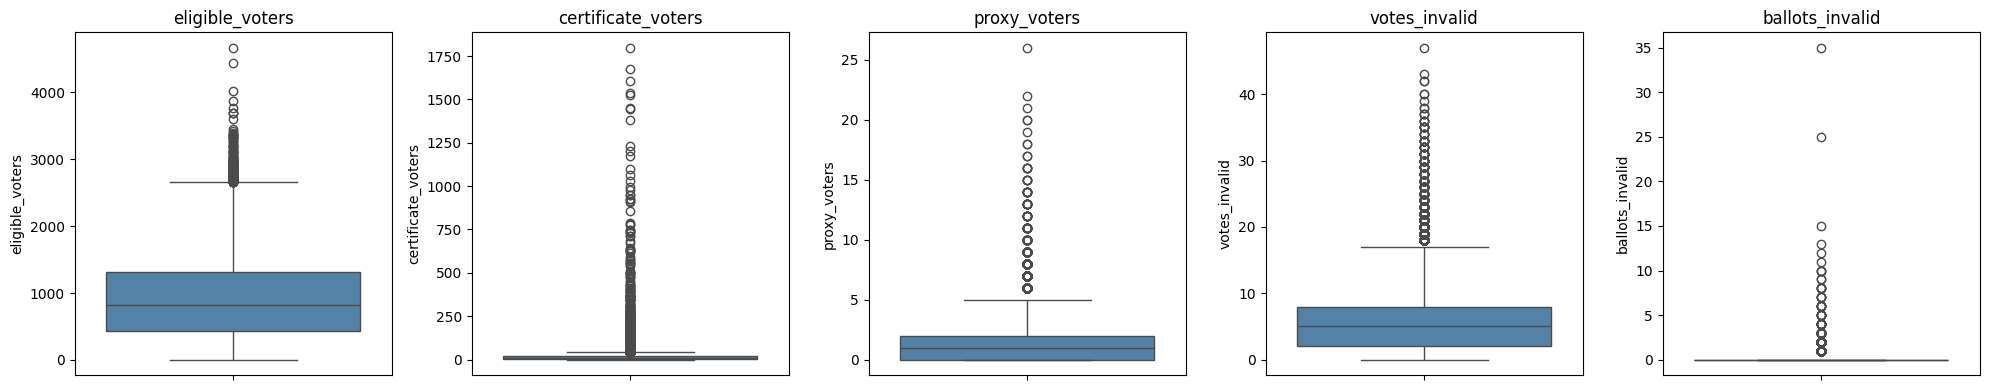

In [28]:
outlier_check_cols = ["eligible_voters", "certificate_voters", "proxy_voters", "votes_invalid", "ballots_invalid"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, outlier_check_cols):
    sns.boxplot(y=df[col], ax=ax, color="steelblue")
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [29]:
# What do the most extreme polling stations look like? (real data or errors?)
df.nlargest(10, "certificate_voters")[
    ["municipality", "district_type", "eligible_voters", "issued_total", "certificate_voters"]
]

,municipality,district_type,eligible_voters,issued_total,certificate_voters
16267,zagranica,zagranica,2056.0,1797.0,1797.0
21338,m. Krynica Morska,stały,3390.0,3001.0,1675.0
31109,gm. Kołobrzeg,stały,2399.0,2216.0,1608.0
31394,gm. Darłowo,stały,2436.0,2247.0,1535.0
31126,gm. Ustronie Morskie,stały,2653.0,2361.0,1527.0
31161,gm. Mielno,stały,2398.0,2177.0,1453.0
31421,gm. Postomino,stały,2174.0,2025.0,1445.0
16582,zagranica,zagranica,4443.0,3849.0,1382.0
30914,gm. Rewal,stały,2728.0,2403.0,1232.0
31373,m. Darłowo,stały,2182.0,1957.0,1202.0


In [30]:
# Which count columns are almost always 0? They carry almost no information.
count_cols = [
    "postal_packages_sent", "proxy_voters", "certificate_voters", "return_envelopes",
    "envelopes_no_statement", "envelopes_unsigned", "envelopes_no_inner",
    "envelopes_unsealed", "envelopes_in_box", "ballots_from_postal",
    "votes_invalid_both_X", "votes_invalid_no_X",
]
zeros = (df[count_cols] == 0).mean().sort_values(ascending=False).round(3)
zeros

,0
envelopes_no_inner,0.999
envelopes_unsealed,0.999
envelopes_unsigned,0.998
envelopes_no_statement,0.982
ballots_from_postal,0.809
envelopes_in_box,0.809
return_envelopes,0.798
postal_packages_sent,0.792
proxy_voters,0.480
votes_invalid_both_X,0.216


In [31]:
# Would a log transformation help? Compare skewness before and after log1p.
skew_cols = ["eligible_voters", "certificate_voters", "proxy_voters", "votes_invalid", "ballots_invalid"]
pd.DataFrame({
    "skew_raw": df[skew_cols].skew(),
    "skew_log1p": np.log1p(df[skew_cols]).skew(),
}).round(2)

,skew_raw,skew_log1p
eligible_voters,0.69,-1.14
certificate_voters,18.40,-0.04
proxy_voters,2.37,0.68
votes_invalid,1.44,-0.34
ballots_invalid,33.65,8.03


In [32]:
# Backup for the before/after comparison (created only once, so re-running this cell does not overwrite it)
if "df_before_outliers" not in globals():
    df_before_outliers = df.copy()

# Winsorization (clip to 1st and 99th percentile)
winsor_cols = ["certificate_voters", "proxy_voters"]
for col in winsor_cols:
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)

# Drop near-constant columns (>= 98% zeros); errors="ignore" makes re-running safe
near_constant = zeros[zeros >= 0.98].index.tolist()
print("Dropped columns (>= 98% zeros):", near_constant)
df = df.drop(columns=near_constant, errors="ignore")

print("Rows kept:", len(df), "| shape:", df.shape)

Dropped columns (>= 98% zeros): ['envelopes_no_inner', 'envelopes_unsealed', 'envelopes_unsigned', 'envelopes_no_statement']
Rows kept: 32038 | shape: (32038, 30)


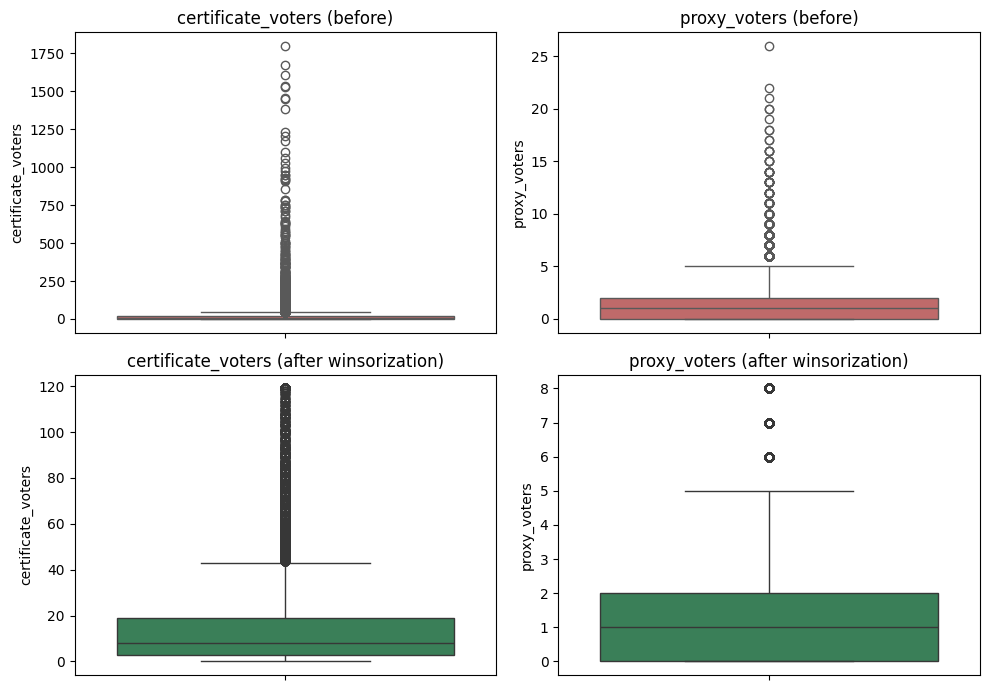

,mean,std,min,max
certificate_voters,14.48,18.90,0.0,119.0
proxy_voters,1.22,1.67,0.0,8.0


In [33]:
# Before / after comparison
fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for j, col in enumerate(winsor_cols):
    sns.boxplot(y=df_before_outliers[col], ax=axes[0, j], color="indianred")
    axes[0, j].set_title(f"{col} (before)")
    sns.boxplot(y=df[col], ax=axes[1, j], color="seagreen")
    axes[1, j].set_title(f"{col} (after winsorization)")
plt.tight_layout()
plt.show()

df[winsor_cols].describe().T[["mean", "std", "min", "max"]].round(2)

**Outliers were examined with boxplots, extreme-value inspection, and zero-share analysis.**

- **Many count variables are zero-inflated and right-skewed (postal voting, proxy votes, invalid ballots). Extreme values mostly correspond to real large or special stations (cities, hospitals, abroad), not data errors.**
- **Winsorization (clipping to the 1st–99th percentile) was applied to `certificate_voters` and `proxy_voters` to limit the influence of extremes without deleting rows.**
- **Columns with ≥ 98% zeros were dropped, as they carry almost no information.**

**This approach preserves the full set of polling stations while reducing the impact of heavy tails on later analysis and modelling.**

# FEATURE ENGINEERING

In [34]:
eps = 1e-9  # protection against division by zero

df["turnout"] = df["issued_total"] / (df["eligible_voters"] + eps)
df["pct_invalid_votes"] = df["votes_invalid"] / (df["ballots_valid"] + eps)
df["pct_invalid_ballots"] = df["ballots_invalid"] / (df["ballots_from_box"] + eps)
df["share_proxy"] = df["proxy_voters"] / (df["issued_total"] + eps)
df["share_certificate"] = df["certificate_voters"] / (df["issued_total"] + eps)
df["share_postal"] = df["postal_packages_sent"] / (df["eligible_voters"] + eps)
df["pct_unused_ballots"] = df["ballots_unused"] / (df["ballots_received"] + eps)

# Result features (for EDA only, NOT for the model - they leak the target)
df["pct_nawrocki"] = df["nawrocki"] / (df["votes_valid"] + eps)
df["nawrocki_margin"] = df["pct_nawrocki"] - (1 - df["pct_nawrocki"])

In [35]:
# Polling station size group (categorical feature)
df["district_size"] = pd.cut(
    df["eligible_voters"],
    bins=[-1, 500, 1000, 2000, np.inf],
    labels=["small (<=500)", "medium (501-1000)", "large (1001-2000)", "very large (>2000)"],
).astype(str)

df["district_size"].value_counts()

,count
district_size,
large (1001-2000),11534
small (<=500),9673
medium (501-1000),9370
very large (>2000),1461


In [36]:
# Ratios can have extreme values too (e.g. tiny hospital stations), so winsorize them as in step 5.
ratio_cols = ["turnout", "pct_invalid_votes", "pct_invalid_ballots", "share_proxy",
              "share_certificate", "share_postal", "pct_unused_ballots"]
for col in ratio_cols:
    low, high = df[col].quantile([0.01, 0.99])
    df[col] = df[col].clip(low, high)

df[ratio_cols + ["pct_nawrocki"]].describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
turnout,0.692,0.093,0.367,0.899
pct_invalid_votes,0.009,0.008,0.000,0.059
pct_invalid_ballots,0.000,0.000,0.000,0.001
share_proxy,0.002,0.003,0.000,0.012
share_certificate,0.021,0.023,0.000,0.145
share_postal,0.000,0.001,0.000,0.004
pct_unused_ballots,0.308,0.116,0.071,0.754
pct_nawrocki,0.570,0.178,0.000,1.000


**New features were created to capture more meaningful patterns:**

**Contextual / structural features (safe for modelling):**
- **`turnout` – participation rate**
- **`pct_invalid_votes`, `pct_invalid_ballots` – quality of voting**
- **`share_proxy`, `share_certificate`, `share_postal` – alternative voting methods**
- **`pct_unused_ballots` – organisational aspect**
- **`district_size` – station size category**

**Result features (for EDA only – data leakage):**
- **`pct_nawrocki`, `nawrocki_margin`**

**Ratio features were also winsorized to handle extreme values from very small stations (e.g. hospitals).**

**All engineered features are now available for exploratory analysis.  
Leakage features must not be used if the goal is to predict `winner`.**

# EXPLORATORY DATA ANALYSIS

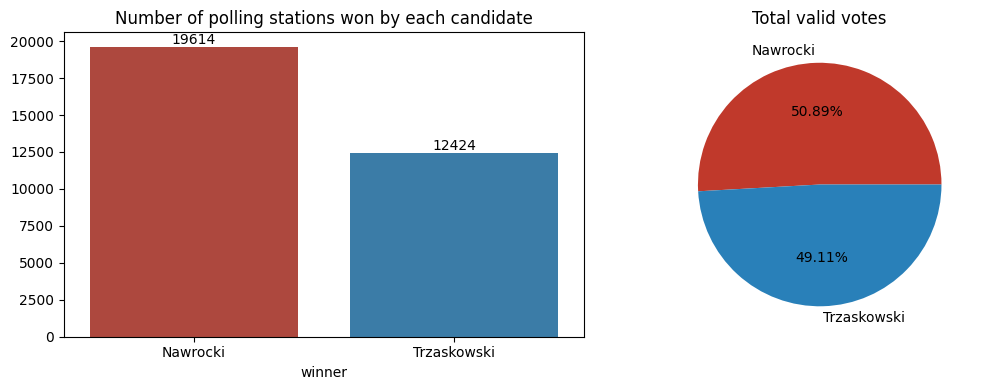

In [37]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts = df["winner"].map({1: "Nawrocki", 0: "Trzaskowski"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, hue=counts.index,
            palette=["#c0392b", "#2980b9"], legend=False, ax=ax[0])
ax[0].set_title("Number of polling stations won by each candidate")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v}", ha="center", va="bottom")

votes = df[["nawrocki", "trzaskowski"]].sum()
ax[1].pie(votes, labels=["Nawrocki", "Trzaskowski"], autopct="%1.2f%%", colors=["#c0392b", "#2980b9"])
ax[1].set_title("Total valid votes")
plt.tight_layout()
plt.show()

**Nawrocki won 19,614 polling stations and Trzaskowski won 12,424 (about 61% vs 39%). In total valid votes the split is almost even (50.89% vs 49.11%). Nawrocki won more stations, but Trzaskowski's stations tend to be larger, so the overall result is close. The classes are moderately imbalanced, so accuracy alone is not a good metric for a model.**

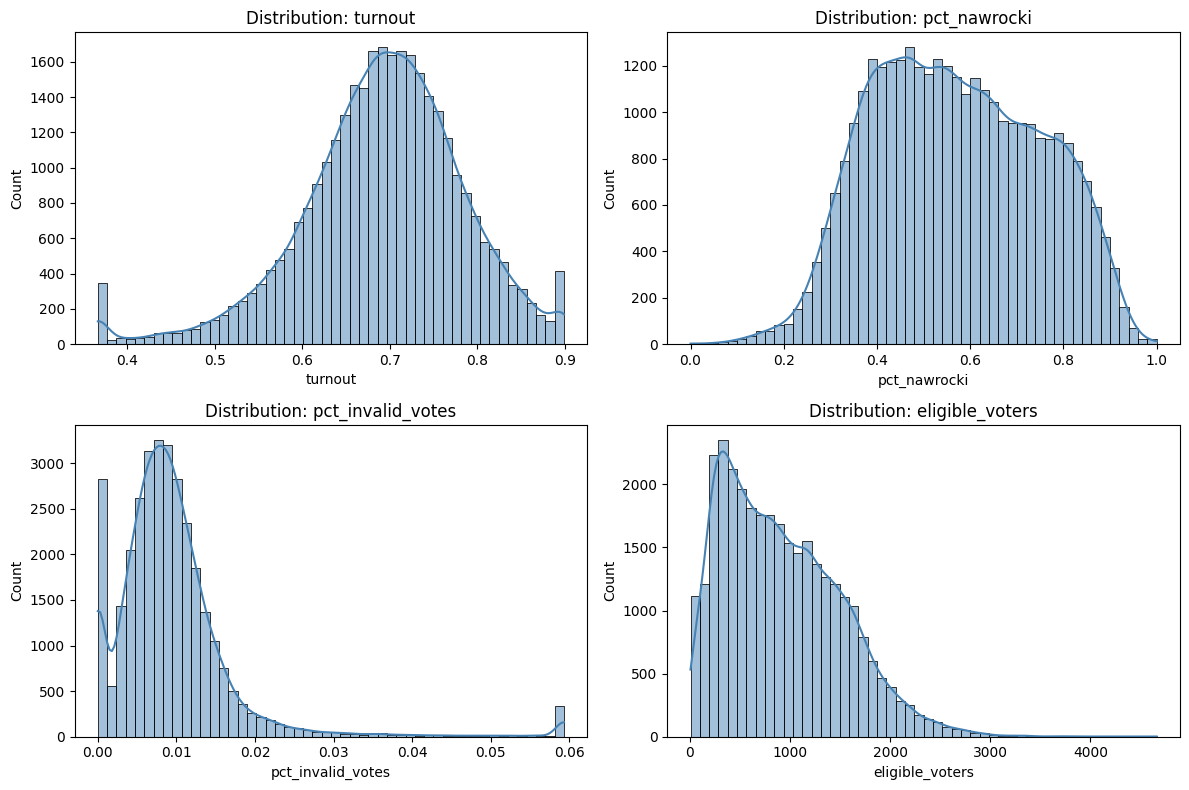

In [38]:
cols = ["turnout", "pct_nawrocki", "pct_invalid_votes", "eligible_voters"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(df[col], bins=50, kde=True, ax=ax, color="steelblue")
    ax.set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()

**Turnout is roughly bell-shaped with a peak around 0.70 and a longer tail toward low turnout. The two spikes at about 0.37 and 0.90 are artifacts of winsorization, not real stations. pct_nawrocki is wide and flat, from about 0.2 to 0.95, with a shoulder near 0.8. This suggests two groups of stations (urban and rural) rather than one uniform population.**

**Most stations have under 1.5% invalid votes, with a peak around 0.8%. The bar at 0 is stations with no invalid votes, and the bar at 0.06 is the winsorization cap. eligible_voters is right-skewed. Most stations are small (about 300 to 400 voters), and a few reach over 4,000.**

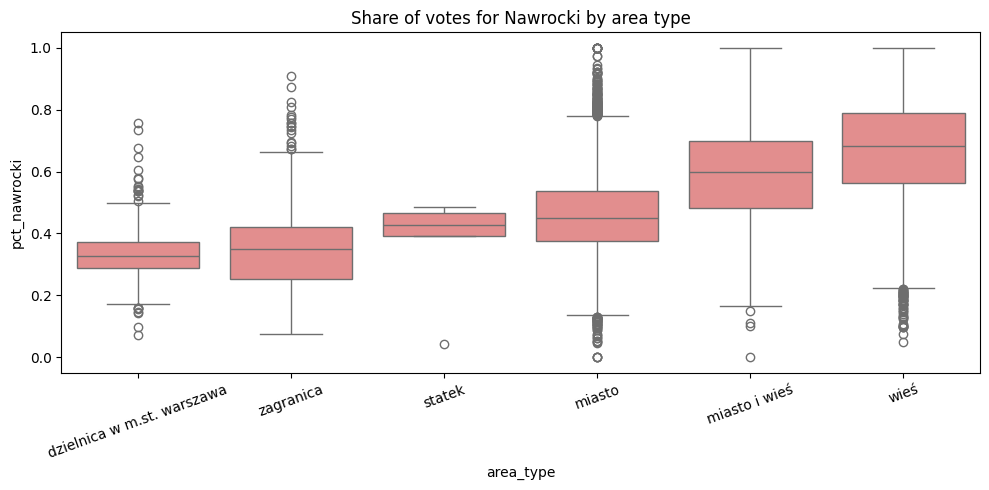

In [39]:
order = df.groupby("area_type")["pct_nawrocki"].median().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x="area_type", y="pct_nawrocki", order=order, color="lightcoral")
plt.xticks(rotation=20)
plt.title("Share of votes for Nawrocki by area type")
plt.tight_layout()
plt.show()

**Median support rises from urban to rural: Warsaw districts (about 0.33), abroad (about 0.35), ship (about 0.43), city (about 0.45), city and village (about 0.60), village (about 0.68). The gap between Warsaw and rural stations is roughly 35 percentage points. The "ship" category has very few observations, so its result is unreliable.**

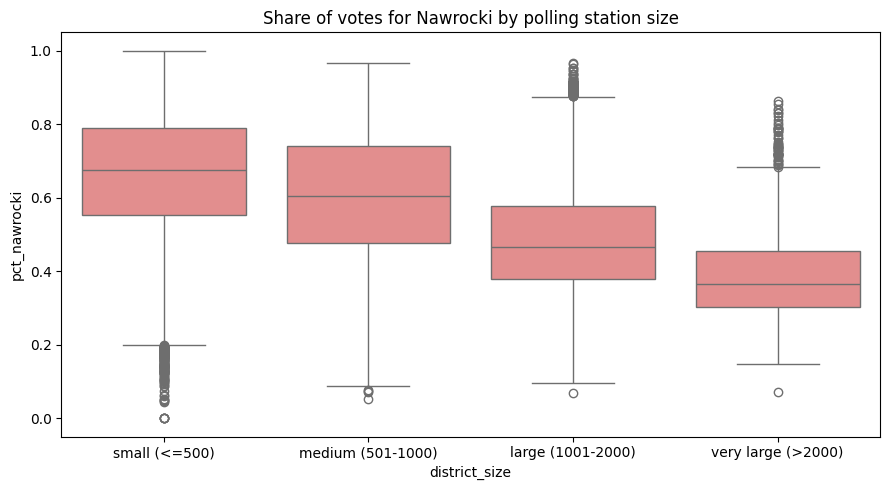

In [40]:
size_order = ["small (<=500)", "medium (501-1000)", "large (1001-2000)", "very large (>2000)"]
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="district_size", y="pct_nawrocki", order=size_order, color="lightcoral")
plt.title("Share of votes for Nawrocki by polling station size")
plt.tight_layout()
plt.show()

**Support for Nawrocki falls steadily as stations get larger: median about 0.67 for small, 0.60 for medium, 0.47 for large and 0.37 for very large stations. Station size is a strong predictor, but it is closely tied to the urban/rural divide.**

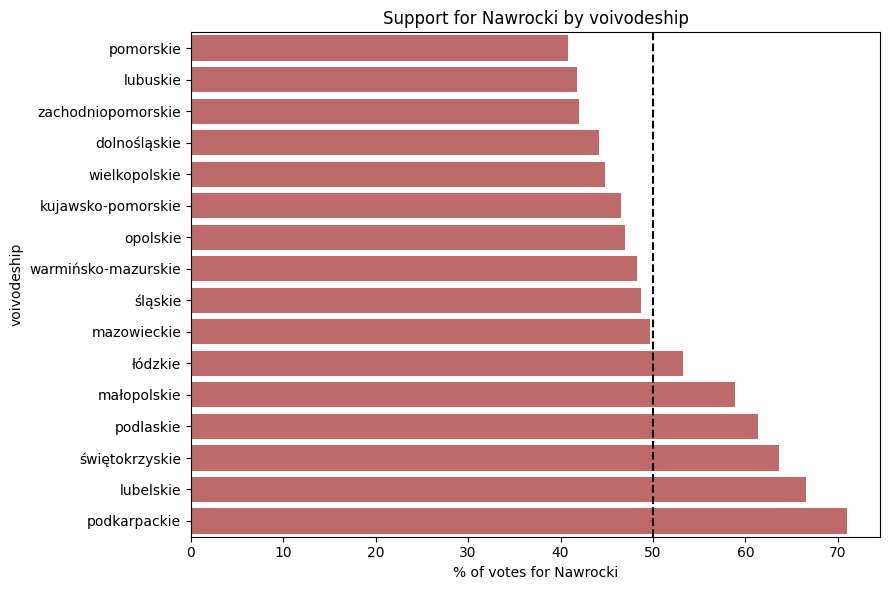

In [41]:
woj = df[df["voivodeship"] != "abroad/ship"].groupby("voivodeship")[["nawrocki", "votes_valid"]].sum()
woj["pct"] = woj["nawrocki"] / woj["votes_valid"] * 100
woj = woj.sort_values("pct")

plt.figure(figsize=(9, 6))
sns.barplot(x=woj["pct"], y=woj.index, color="indianred")
plt.axvline(50, color="black", linestyle="--")
plt.xlabel("% of votes for Nawrocki")
plt.title("Support for Nawrocki by voivodeship")
plt.tight_layout()
plt.show()

**Support is lowest in the north and west (pomorskie about 41%) and highest in the southeast (podkarpackie about 71%). Mazowieckie and śląskie are close to 50%. The region is clearly informative, showing a west/north vs east/southeast divide.**

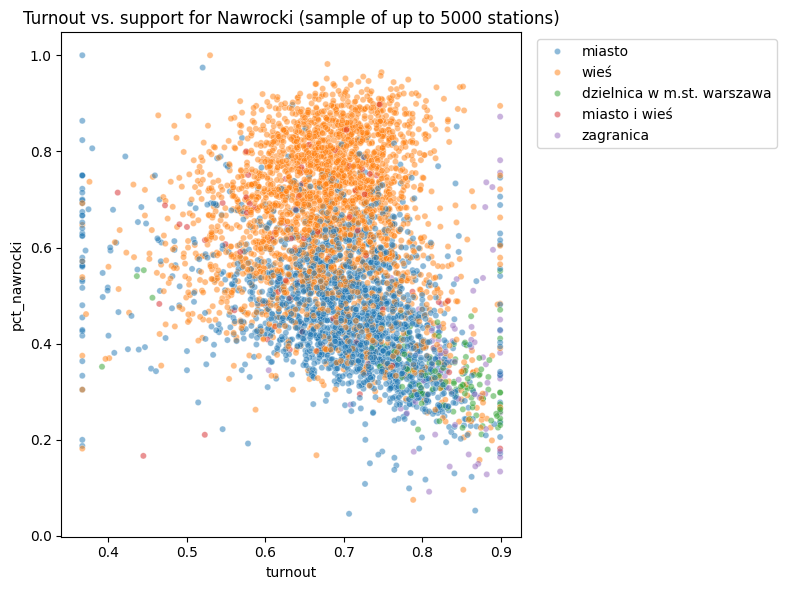

In [42]:
sample = df.sample(min(5000, len(df)), random_state=42)
plt.figure(figsize=(8, 6))
sns.scatterplot(data=sample, x="turnout", y="pct_nawrocki", hue="area_type", alpha=0.5, s=20)
plt.title("Turnout vs. support for Nawrocki (sample of up to 5000 stations)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**The cloud slopes downward: higher turnout goes with lower support for Nawrocki. Rural stations (orange) sit at the top, urban ones (blue) lower, and Warsaw districts (green) in the bottom right with high turnout. The slope is mostly driven by the urban/rural difference rather than by turnout itself. The vertical stripes at 0.37 and 0.90 come from winsorization.**

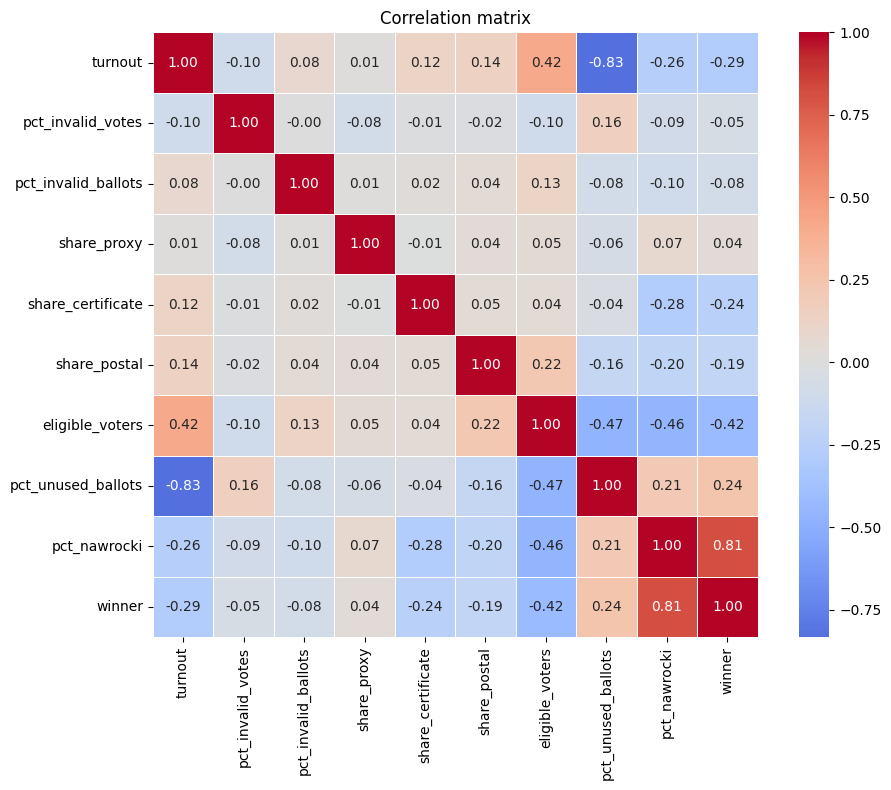

In [43]:
corr_cols = ["turnout", "pct_invalid_votes", "pct_invalid_ballots", "share_proxy",
             "share_certificate", "share_postal", "eligible_voters",
             "pct_unused_ballots", "pct_nawrocki", "winner"]
corr = df[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=0.5)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

**The strongest relationships with the outcome are eligible_voters (−0.46 with pct_nawrocki), share_certificate (−0.28) and turnout (−0.26). turnout and pct_unused_ballots are strongly negatively correlated (−0.83), so they carry nearly the same information. winner and pct_nawrocki correlate at 0.81, which is expected since one comes directly from the other (data leakage if used as a feature).**

In [44]:
# Correlation of each feature with the target (winner) and with the continuous outcome (pct_nawrocki)
target_corr = pd.DataFrame({
    "with_winner": corr["winner"],
    "with_pct_nawrocki": corr["pct_nawrocki"],
}).drop(index=["winner", "pct_nawrocki"])
target_corr.sort_values("with_pct_nawrocki", key=abs, ascending=False).round(3)

,with_winner,with_pct_nawrocki
eligible_voters,-0.420,-0.464
share_certificate,-0.241,-0.283
turnout,-0.287,-0.264
pct_unused_ballots,0.242,0.213
share_postal,-0.186,-0.200
pct_invalid_ballots,-0.080,-0.096
pct_invalid_votes,-0.046,-0.092
share_proxy,0.036,0.073


In [45]:
# Highly correlated feature pairs (|r| > 0.8): candidates for removal before modelling
feat_corr = df[corr_cols].drop(columns=["pct_nawrocki", "winner"]).corr().abs()
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
high = upper.stack()
high[high > 0.8].sort_values(ascending=False)

,,0
turnout,pct_unused_ballots,0.83289


# HYPOTHESIS TESTING AND STATISTICAL INFERENCE

In [46]:
#p-value < 0.05 → reject H₀, p-value >= 0.05 → do not reject H₀
from scipy import stats
import pandas as pd
import numpy as np

alpha = 0.05

## Hypothesis for one sample test

### Is the mean voter turnout across polling stations greater than 65%?

H₀: The mean voter turnout across polling stations is 65%.

H₁: The mean voter turnout across polling stations is higher than 65%.

In [47]:
alpha = 0.05
mu_0 = 0.65

turnout = df["turnout"].dropna()

# Descriptive statistics
print("Number of observations:", len(turnout))
print("Mean turnout:", turnout.mean())
print("Standard deviation:", turnout.std())

# One-sample t-test
t_stat, p_value = stats.ttest_1samp(
    turnout,
    popmean=mu_0,
    alternative="greater"
)

print("\nOne-sample t-test")
print("H0: mean turnout = 0.65")
print("H1: mean turnout > 0.65")
print("Significance level alpha =", alpha)
print("Test statistic =", t_stat)
print("P-value =", p_value)

if p_value < alpha:
    print("\nDecision: Reject H0")
    print("Conclusion: The mean voter turnout is significantly greater than 65%.")
else:
    print("\nDecision: Do not reject H0")
    print("Conclusion: There is not enough evidence to conclude that the mean voter turnout is greater than 65%.")

Number of observations: 32038
Mean turnout: 0.6915580545192553
Standard deviation: 0.09326979597187338

One-sample t-test
H0: mean turnout = 0.65
H1: mean turnout > 0.65
Significance level alpha = 0.05
Test statistic = 79.75297277571264
P-value = 0.0

Decision: Reject H0
Conclusion: The mean voter turnout is significantly greater than 65%.


A one-sample t-test was conducted to determine whether the mean voter turnout was significantly greater than 65%.

α = 0.05

t = 79.75

P = 0.0

Since the p-value is lower than the significance level of 0.05, we reject the null hypothesis.

## Hypothesis for two samples test

### The analysis tests whether candidate support differs significantly between urban and rural polling stations.

H₀: The mean share of votes for Nawrocki is the same in rural and urban polling stations.

 H₁: The mean share of votes for Nawrocki differs between rural and urban polling stations.

In [48]:
alpha = 0.05

urban = df.loc[
    df["area_type"] == "miasto",
    "pct_nawrocki"
].dropna()

rural = df.loc[
    df["area_type"] == "wieś",
    "pct_nawrocki"
].dropna()

# Descriptive statistics
print("URBAN")
print("Number of observations:", len(urban))
print("Mean support:", urban.mean())
print("Standard deviation:", urban.std())

print("\nRURAL")
print("Number of observations:", len(rural))
print("Mean support:", rural.mean())
print("Standard deviation:", rural.std())

# Welch's t-test
t_stat, p_value = stats.ttest_ind(
    urban,
    rural,
    equal_var=False
)

print("\nWelch's two-sample t-test")
print("H0: mean urban support = mean rural support")
print("H1: mean urban support != mean rural support")
print("Significance level alpha =", alpha)
print("Test statistic =", t_stat)
print("P-value =", p_value)

if p_value < alpha:
    print("\nDecision: Reject H0")
    print("Conclusion: The mean share of votes for Nawrocki differs significantly between urban and rural polling stations.")
else:
    print("\nDecision: Do not reject H0")
    print("Conclusion: There is not enough evidence to conclude that mean support differs between urban and rural polling stations.")

difference = rural.mean() - urban.mean()

print("Difference in mean support:")
print(difference)
print("Difference in percentage points:")
print(difference * 100)

URBAN
Number of observations: 12762
Mean support: 0.46189135586605773
Standard deviation: 0.12293213067649371

RURAL
Number of observations: 17350
Mean support: 0.6665365684580882
Standard deviation: 0.15323939943462758

Welch's two-sample t-test
H0: mean urban support = mean rural support
H1: mean urban support != mean rural support
Significance level alpha = 0.05
Test statistic = -128.46622814946952
P-value = 0.0

Decision: Reject H0
Conclusion: The mean share of votes for Nawrocki differs significantly between urban and rural polling stations.
Difference in mean support:
0.20464521259203045
Difference in percentage points:
20.464521259203046


Welch’s two-sample t-test showed that the mean support for Nawrocki differed significantly between urban and rural polling stations

α = 0.05

t = -128.47

p < 0.001

Mean support was 46.19% in urban polling stations and 66.65% in rural polling stations, corresponding to a difference of approximately 20.46 percentage points.

## Chi-square test

### Is the winner of a polling station associated with the voivodeship?

H₀: The winner of a polling station is independent of voivodeship.

H₁: There is an association between the winner of a polling station and the voivodeship.

Contigency table for chi-square test

In [49]:
# Exclude polling stations located abroad or on ships
chi_df = df[df["voivodeship"] != "abroad/ship"].copy()

# Create contingency table
contingency_table = pd.crosstab(
    chi_df["voivodeship"],
    chi_df["winner"]
)

# Change column names for readability
contingency_table.columns = ["Trzaskowski", "Nawrocki"]

print(contingency_table)

                     Trzaskowski  Nawrocki
voivodeship                               
dolnośląskie                1278      1066
kujawsko-pomorskie           911      1019
lubelskie                    145      2054
lubuskie                     597       299
mazowieckie                 1448      2579
małopolskie                  664      2087
opolskie                     486       535
podkarpackie                  81      1859
podlaskie                    208       863
pomorskie                   1009       722
warmińsko-mazurskie          574       735
wielkopolskie               1357      1486
zachodniopomorskie           891       516
łódzkie                      631      1307
śląskie                     1531      1344
świętokrzyskie               157      1086


In [50]:
alpha = 0.05

chi2_stat, p_value, dof, expected = stats.chi2_contingency(
    contingency_table
)

print("\nChi-square test of independence")
print("H0: Winner and voivodeship are independent")
print("H1: Winner and voivodeship are associated")

print("\nSignificance level alpha =", alpha)
print("Chi-square statistic =", chi2_stat)
print("Degrees of freedom =", dof)
print("P-value =", p_value)

# Decision
if p_value < alpha:
    print("\nDecision: Reject H0")
    print(
        "Conclusion: There is a statistically significant "
        "association between the voivodeship and the winner "
        "of a polling station."
    )
else:
    print("\nDecision: Do not reject H0")
    print(
        "Conclusion: There is not enough evidence to conclude "
        "that the voivodeship and the winner of a polling "
        "station are associated."
    )

# Expected frequencies
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("\nExpected frequencies:")
print(expected_df)

print("\nMinimum expected frequency:", expected_df.min().min())


Chi-square test of independence
H0: Winner and voivodeship are independent
H1: Winner and voivodeship are associated

Significance level alpha = 0.05
Chi-square statistic = 4412.003877721167
Degrees of freedom = 15
P-value = 0.0

Decision: Reject H0
Conclusion: There is a statistically significant association between the voivodeship and the winner of a polling station.

Expected frequencies:
                     Trzaskowski     Nawrocki
voivodeship                                  
dolnośląskie          889.864933  1454.135067
kujawsko-pomorskie    732.695956  1197.304044
lubelskie             834.817827  1364.182173
lubuskie              340.153148   555.846852
mazowieckie          1528.790991  2498.209009
małopolskie          1044.376463  1706.623537
opolskie              387.607550   633.392450
podkarpackie          736.492308  1203.507692
podlaskie             406.589310   664.410690
pomorskie             657.148549  1073.851451
warmińsko-mazurskie   496.942490   812.057510
wielko

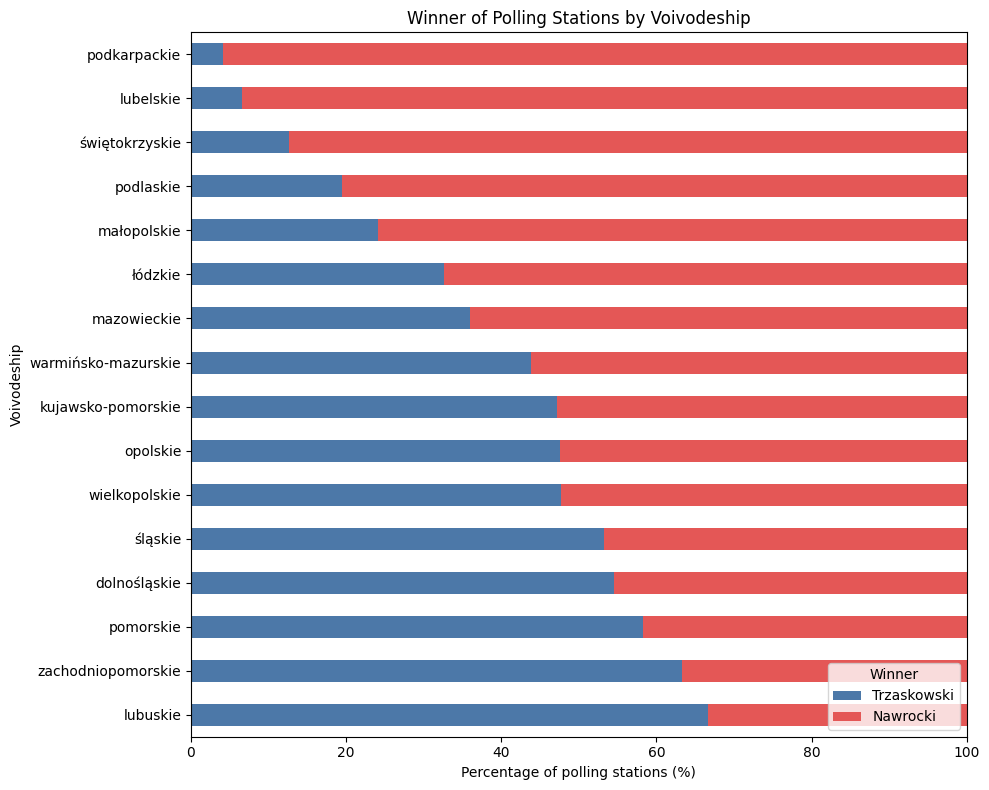

In [51]:
# Calculate percentage of polling stations won by each candidate
winner_percentages = pd.crosstab(
    chi_df["voivodeship"],
    chi_df["winner"],
    normalize="index"
) * 100

# Rename columns
winner_percentages.columns = ["Trzaskowski", "Nawrocki"]

# Sort by Nawrocki's percentage for better readability
winner_percentages = winner_percentages.sort_values(
    by="Nawrocki",
    ascending=True
)

# Plot
ax = winner_percentages.plot(
    kind="barh",
    stacked=True,
    figsize=(10, 8),
    color=["#4C78A8", "#E45756"]
)

plt.xlabel("Percentage of polling stations (%)")
plt.ylabel("Voivodeship")
plt.title("Winner of Polling Stations by Voivodeship")
plt.legend(title="Winner", loc="lower right")

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

The chi-square test of independence showed a statistically significant association between the voivodeship and the winner of a polling station.

 χ²(15) = 4412.00

 p < 0.001.

 Therefore, the null hypothesis of independence was rejected. This means that the distribution of polling stations won by Trzaskowski and Nawrocki differs significantly across voivodeships.

# PREDICTIVE MODELLING AND REGRESSION ANALYSIS

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats

ALPHA = 0.05
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Libraries loaded.")

Libraries loaded.


In [53]:
df_reg = df.copy()
df_reg["eligible_voters_k"] = df_reg["eligible_voters"] / 1000
df_reg["is_rural"] = (df_reg["area_type"] == "wieś").astype(int)

print("Dataset shape:", df_reg.shape)
display(df_reg[["eligible_voters_k", "turnout", "share_certificate", "share_postal",
                "share_proxy", "pct_invalid_votes", "is_rural", "pct_nawrocki", "winner"]].head())

Dataset shape: (32038, 42)


,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural,pct_nawrocki,winner
0,1.678,0.707390,0.016849,0.000000,0.000842,0.007582,0,0.494058,0
1,1.269,0.717888,0.021954,0.000788,0.002195,0.008782,0,0.427464,0
2,1.358,0.733432,0.019076,0.000736,0.002008,0.003012,0,0.440081,0
3,1.354,0.726736,0.010163,0.000000,0.001016,0.009146,0,0.418462,0
4,1.195,0.716318,0.016355,0.000000,0.001168,0.007009,0,0.390588,0


# SIMPLE LINEAR REGRESSION

In [54]:
simple_data = df_reg[["eligible_voters_k", "pct_nawrocki"]].copy()

for column in simple_data.columns:
    simple_data[column] = pd.to_numeric(simple_data[column], errors="coerce")

simple_data = simple_data.dropna()

print("Dataset shape:", simple_data.shape)
display(simple_data.head())

print("Summary statistics")
display(simple_data.describe())

Dataset shape: (32038, 2)


,eligible_voters_k,pct_nawrocki
0,1.678,0.494058
1,1.269,0.427464
2,1.358,0.440081
3,1.354,0.418462
4,1.195,0.390588


Summary statistics


,eligible_voters_k,pct_nawrocki
count,32038.000000,32038.000000
mean,0.915415,0.569768
std,0.587057,0.177696
min,0.006000,0.000000
25%,0.426250,0.427794
50%,0.828500,0.560000
75%,1.318000,0.712256
max,4.662000,1.000000


In [55]:
x = simple_data["eligible_voters_k"]
y = simple_data["pct_nawrocki"]

r, correlation_p = stats.pearsonr(x, y)

print("Pearson correlation test")
print("H0: ρ = 0")
print("H1: ρ ≠ 0")
print(f"Correlation coefficient (r) = {r:.4f}")
print(f"p-value = {correlation_p:.6g}")

if correlation_p < ALPHA:
    print(f"p-value < {ALPHA}: Reject H0. There is evidence of a statistically significant linear correlation.")
else:
    print(f"p-value >= {ALPHA}: Do not reject H0. There is insufficient evidence of a statistically significant linear correlation.")

Pearson correlation test
H0: ρ = 0
H1: ρ ≠ 0
Correlation coefficient (r) = -0.4642
p-value = 0
p-value < 0.05: Reject H0. There is evidence of a statistically significant linear correlation.


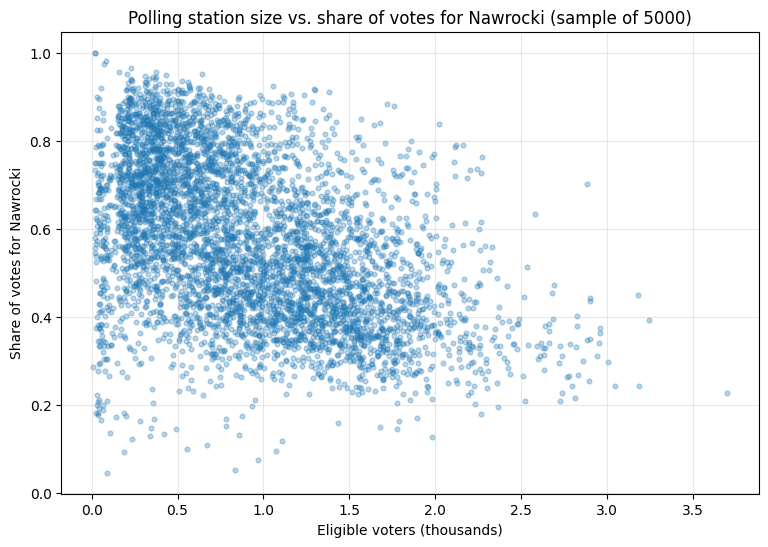

In [56]:
sample_simple = simple_data.sample(min(5000, len(simple_data)), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 6))
plt.scatter(sample_simple["eligible_voters_k"], sample_simple["pct_nawrocki"], alpha=0.3, s=12)
plt.xlabel("Eligible voters (thousands)")
plt.ylabel("Share of votes for Nawrocki")
plt.title("Polling station size vs. share of votes for Nawrocki (sample of 5000)")
plt.grid(True, alpha=0.3)
plt.show()

In [57]:
# Train/test split
X = simple_data[["eligible_voters_k"]]
y = simple_data["pct_nawrocki"]

X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training observations:", len(X_train_s))
print("Testing observations:", len(X_test_s))
print(f"Training proportion: {len(X_train_s) / len(simple_data):.0%}")
print(f"Testing proportion:  {len(X_test_s) / len(simple_data):.0%}")

# Fit linear regression model
simple_model = LinearRegression()
simple_model.fit(X_train_s, y_train_s)

intercept = simple_model.intercept_
slope = simple_model.coef_[0]

print("\nSimple Linear Regression model")
print("Coefficients:")
print(f"Intercept (a) = {intercept:.6f}")
print(f"Slope (b) = {slope:.6f}")

print("\nEstimated regression equation:")
print(f"pct_nawrocki = {intercept:.4f} + ({slope:.6f} × eligible_voters_k)")

# ============================================================
# Using Ordinary Least Squares (OLS) method
# ============================================================
X_train_sm = sm.add_constant(X_train_s)
simple_model_OLS = sm.OLS(y_train_s, X_train_sm).fit()
print(simple_model_OLS.summary())

Training observations: 25630
Testing observations: 6408
Training proportion: 80%
Testing proportion:  20%

Simple Linear Regression model
Coefficients:
Intercept (a) = 0.698093
Slope (b) = -0.140403

Estimated regression equation:
pct_nawrocki = 0.6981 + (-0.140403 × eligible_voters_k)
                            OLS Regression Results                            
Dep. Variable:           pct_nawrocki   R-squared:                       0.217
Model:                            OLS   Adj. R-squared:                  0.217
Method:                 Least Squares   F-statistic:                     7084.
Date:                Thu, 08 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:05:50   Log-Likelihood:                 11046.
No. Observations:               25630   AIC:                        -2.209e+04
Df Residuals:                   25628   BIC:                        -2.207e+04
Df Model:                           1                                         
Co

In [58]:
print("t-test for the eligible_voters_k coefficient")
print("H0: b = 0")
print("H1: b ≠ 0")

t_stat = simple_model_OLS.tvalues["eligible_voters_k"]
p_value = simple_model_OLS.pvalues["eligible_voters_k"]

print(f"t-statistic = {t_stat:.4f}")
print(f"p-value = {p_value:.6g}")

if p_value < ALPHA:
    print(f"p-value < {ALPHA}: Reject H0. Polling station size is a statistically significant predictor of pct_nawrocki.")
else:
    print(f"p-value >= {ALPHA}: Do not reject H0. There is insufficient evidence that polling station size is a significant predictor.")


t-test for the eligible_voters_k coefficient
H0: b = 0
H1: b ≠ 0
t-statistic = -84.1688
p-value = 0
p-value < 0.05: Reject H0. Polling station size is a statistically significant predictor of pct_nawrocki.


In [59]:
print("F-test for the overall regression model")
print("H0: b = 0")
print("H1: b ≠ 0")

f_stat = simple_model_OLS.fvalue
f_p_value = simple_model_OLS.f_pvalue

print(f"F-statistic = {f_stat:.4f}")
print(f"p-value = {f_p_value:.6g}")

if f_p_value < ALPHA:
    print(f"p-value < {ALPHA}: Reject H0. The regression model is statistically significant.")
else:
    print(f"p-value >= {ALPHA}: Do not reject H0. There is insufficient evidence that the regression model is statistically significant.")

F-test for the overall regression model
H0: b = 0
H1: b ≠ 0
F-statistic = 7084.3888
p-value = 0
p-value < 0.05: Reject H0. The regression model is statistically significant.


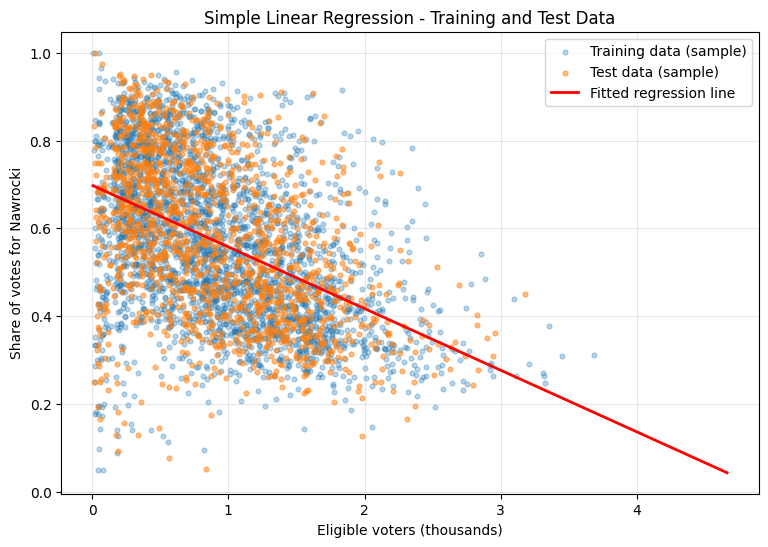

In [60]:
line_x = np.linspace(simple_data["eligible_voters_k"].min(), simple_data["eligible_voters_k"].max(), 200)
line_y = simple_model.predict(pd.DataFrame({"eligible_voters_k": line_x}))

train_plot = X_train_s.assign(y=y_train_s).sample(3000, random_state=RANDOM_STATE)
test_plot = X_test_s.assign(y=y_test_s).sample(min(1500, len(X_test_s)), random_state=RANDOM_STATE)

plt.figure(figsize=(9, 6))
plt.scatter(train_plot["eligible_voters_k"], train_plot["y"], alpha=0.3, s=12, label="Training data (sample)")
plt.scatter(test_plot["eligible_voters_k"], test_plot["y"], alpha=0.5, s=12, label="Test data (sample)")
plt.plot(line_x, line_y, color="red", linewidth=2, label="Fitted regression line")
plt.xlabel("Eligible voters (thousands)")
plt.ylabel("Share of votes for Nawrocki")
plt.title("Simple Linear Regression - Training and Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [61]:
y_pred_s = simple_model.predict(X_test_s)

simple_predictions = X_test_s.copy()
simple_predictions["Actual"] = y_test_s.values
simple_predictions["Predicted"] = y_pred_s
simple_predictions["Residual"] = simple_predictions["Actual"] - simple_predictions["Predicted"]

display(simple_predictions.head(15))

,eligible_voters_k,Actual,Predicted,Residual
12564,0.865,0.632330,0.576644,0.055686
29389,2.432,0.270270,0.356632,-0.086362
11776,1.569,0.416461,0.477800,-0.061339
15985,0.762,0.419250,0.591106,-0.171856
29769,0.174,0.274336,0.673663,-0.399326
29972,1.878,0.390708,0.434416,-0.043707
3105,0.214,0.496296,0.668046,-0.171750
19099,1.060,0.830601,0.549265,0.281336
14461,1.655,0.460197,0.465725,-0.005528
17362,0.218,0.680556,0.667485,0.013071


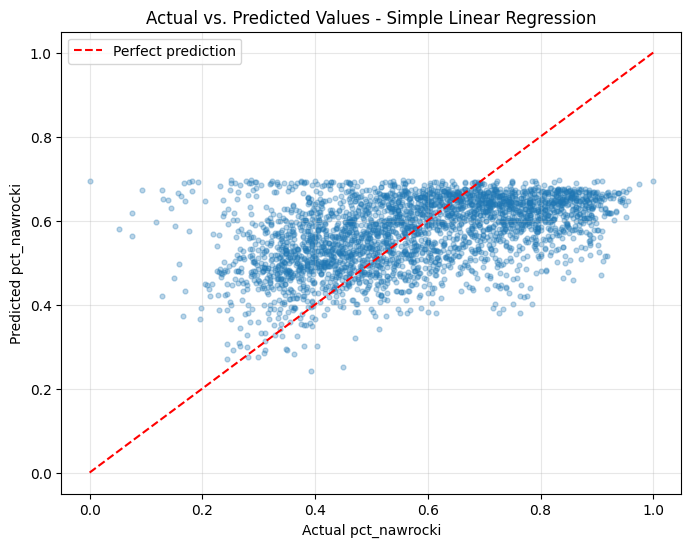

In [62]:
pred_plot = simple_predictions.sample(min(3000, len(simple_predictions)), random_state=RANDOM_STATE)

plt.figure(figsize=(8, 6))
plt.scatter(pred_plot["Actual"], pred_plot["Predicted"], alpha=0.3, s=12)
plt.plot([0, 1], [0, 1], linestyle="--", color="red", label="Perfect prediction")
plt.xlabel("Actual pct_nawrocki")
plt.ylabel("Predicted pct_nawrocki")
plt.title("Actual vs. Predicted Values - Simple Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [63]:
def calculate_mape(y_true, y_pred):
    """
    Mean Absolute Percentage Error (MAPE).
    Observations with actual values equal to zero are excluded to avoid division by zero.
    """
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    nonzero_mask = y_true != 0
    if nonzero_mask.sum() == 0:
        return np.nan
    return np.mean(np.abs((y_true[nonzero_mask] - y_pred[nonzero_mask]) / y_true[nonzero_mask])) * 100

mae = mean_absolute_error(y_test_s, y_pred_s)
mse = mean_squared_error(y_test_s, y_pred_s)
rmse = np.sqrt(mse)
r_squared = r2_score(y_test_s, y_pred_s)
mape = calculate_mape(y_test_s, y_pred_s)

simple_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "MAPE (%)", "R-squared"],
    "Value": [mae, mse, rmse, mape, r_squared]
})
display(simple_metrics)

,Metric,Value
0,MAE,0.128095
1,MSE,0.024950
2,RMSE,0.157957
3,MAPE (%),27.361370
4,R-squared,0.210959


In [64]:
new_stations_simple = pd.DataFrame({"eligible_voters_k": [0.3, 1.0, 2.5]})
new_stations_simple["predicted_pct_nawrocki"] = simple_model.predict(new_stations_simple[["eligible_voters_k"]])
display(new_stations_simple)

,eligible_voters_k,predicted_pct_nawrocki
0,0.3,0.655972
1,1.0,0.557690
2,2.5,0.347085


# MULTIPLE LINEAR REGRESSION

In [65]:
multiple_predictors = ["eligible_voters_k", "turnout", "share_certificate", "is_rural"]
multiple_data = df_reg[multiple_predictors + ["pct_nawrocki"]].copy()

for column in multiple_data.columns:
    multiple_data[column] = pd.to_numeric(multiple_data[column], errors="coerce")

multiple_data = multiple_data.dropna()

print("Dataset shape:", multiple_data.shape)
display(multiple_data.head())
display(multiple_data.describe())

Dataset shape: (32038, 5)


,eligible_voters_k,turnout,share_certificate,is_rural,pct_nawrocki
0,1.678,0.707390,0.016849,0,0.494058
1,1.269,0.717888,0.021954,0,0.427464
2,1.358,0.733432,0.019076,0,0.440081
3,1.354,0.726736,0.010163,0,0.418462
4,1.195,0.716318,0.016355,0,0.390588


,eligible_voters_k,turnout,share_certificate,is_rural,pct_nawrocki
count,32038.000000,32038.000000,32038.000000,32038.000000,32038.000000
mean,0.915415,0.691558,0.020826,0.541544,0.569768
std,0.587057,0.093270,0.022761,0.498279,0.177696
min,0.006000,0.366667,0.000000,0.000000,0.000000
25%,0.426250,0.640155,0.008028,0.000000,0.427794
50%,0.828500,0.697212,0.015504,1.000000,0.560000
75%,1.318000,0.751488,0.025236,1.000000,0.712256
max,4.662000,0.899000,0.144928,1.000000,1.000000


,eligible_voters_k,turnout,share_certificate,is_rural,pct_nawrocki
eligible_voters_k,1.000000,0.415289,0.041628,-0.466915,-0.464180
turnout,0.415289,1.000000,0.122704,-0.193038,-0.263644
share_certificate,0.041628,0.122704,1.000000,-0.221742,-0.283036
is_rural,-0.466915,-0.193038,-0.221742,1.000000,0.591878
pct_nawrocki,-0.464180,-0.263644,-0.283036,0.591878,1.000000


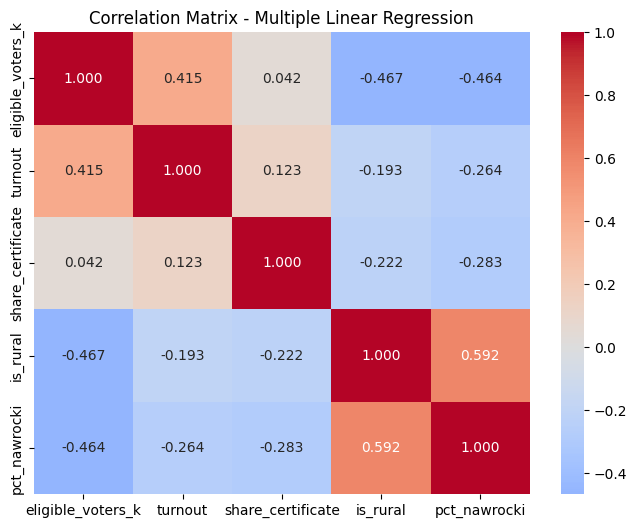

H0: ρ = 0 (no linear correlation)  vs  H1: ρ ≠ 0, α = 0.05


,Variable 1,Variable 2,Correlation (r),p-value,Significant
0,eligible_voters_k,turnout,0.415289,0.000000e+00,Yes
1,eligible_voters_k,share_certificate,0.041628,9.058574e-14,Yes
2,eligible_voters_k,is_rural,-0.466915,0.000000e+00,Yes
3,eligible_voters_k,pct_nawrocki,-0.464180,0.000000e+00,Yes
4,turnout,share_certificate,0.122704,1.054798e-107,Yes
5,turnout,is_rural,-0.193038,1.523325e-266,Yes
6,turnout,pct_nawrocki,-0.263644,0.000000e+00,Yes
7,share_certificate,is_rural,-0.221742,0.000000e+00,Yes
8,share_certificate,pct_nawrocki,-0.283036,0.000000e+00,Yes
9,is_rural,pct_nawrocki,0.591878,0.000000e+00,Yes


In [66]:
correlation_matrix = multiple_data.corr()
display(correlation_matrix)

plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, fmt=".3f", cmap="coolwarm", center=0)
plt.title("Correlation Matrix - Multiple Linear Regression")
plt.show()

# Significance tests for all correlations
correlation_results = []
columns = multiple_data.columns

for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        var1, var2 = columns[i], columns[j]
        pair_data = multiple_data[[var1, var2]].dropna()
        r, p_value = stats.pearsonr(pair_data[var1], pair_data[var2])
        correlation_results.append({
            "Variable 1": var1,
            "Variable 2": var2,
            "Correlation (r)": r,
            "p-value": p_value,
            "Significant": "Yes" if p_value < ALPHA else "No"
        })

print("H0: ρ = 0 (no linear correlation)  vs  H1: ρ ≠ 0, α =", ALPHA)
correlation_significance = pd.DataFrame(correlation_results)
display(correlation_significance)

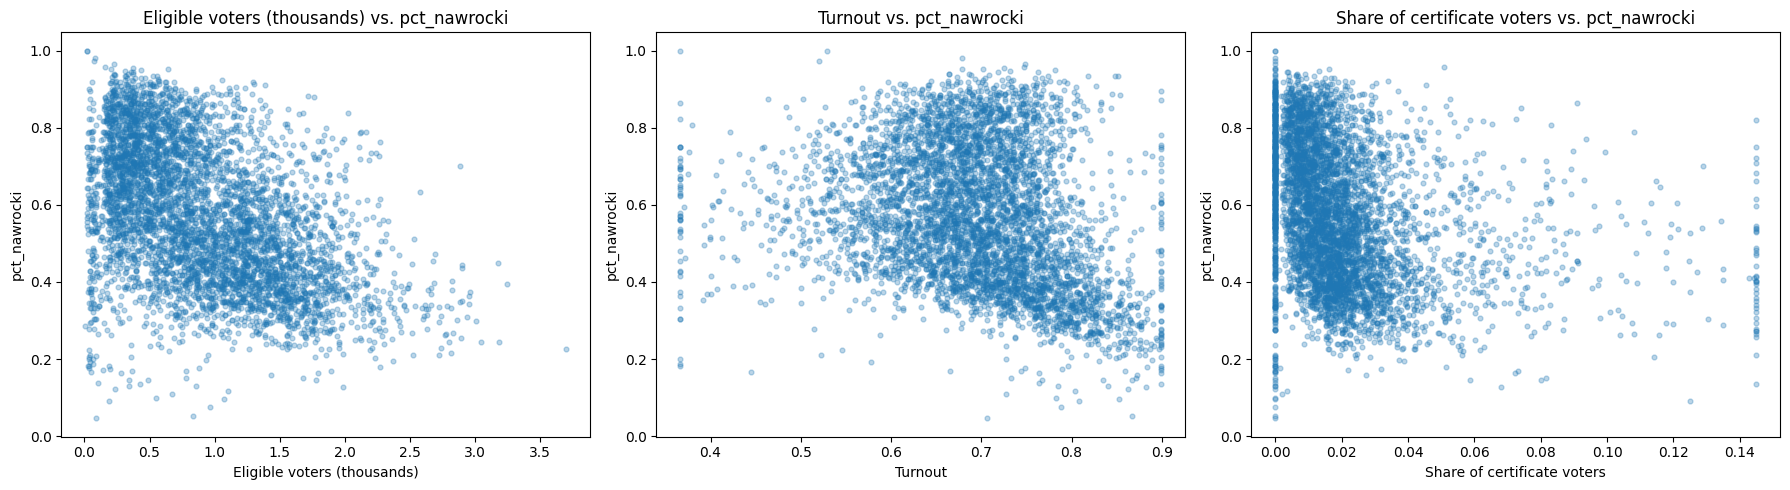

In [67]:
sample_multiple = multiple_data.sample(min(5000, len(multiple_data)), random_state=RANDOM_STATE)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, label in zip(
    axes,
    ["eligible_voters_k", "turnout", "share_certificate"],
    ["Eligible voters (thousands)", "Turnout", "Share of certificate voters"]
):
    ax.scatter(sample_multiple[col], sample_multiple["pct_nawrocki"], alpha=0.3, s=12)
    ax.set_xlabel(label)
    ax.set_ylabel("pct_nawrocki")
    ax.set_title(f"{label} vs. pct_nawrocki")
plt.tight_layout()
plt.show()

In [68]:
# Train/test split
X = multiple_data[multiple_predictors]
y = multiple_data["pct_nawrocki"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE
)

print("Training observations:", len(X_train_m))
print("Testing observations:", len(X_test_m))
print(f"Training proportion: {len(X_train_m) / len(multiple_data):.0%}")
print(f"Testing proportion:  {len(X_test_m) / len(multiple_data):.0%}")

# Multicollinearity check (VIF < 5 means no serious problem)
X_train_m_c = sm.add_constant(X_train_m)
vif = pd.Series(
    [variance_inflation_factor(X_train_m_c.values, i) for i in range(1, X_train_m_c.shape[1])],
    index=multiple_predictors
).round(2)
print("\nVariance Inflation Factors:")
print(vif)

# Fit multiple regression model
multiple_model = LinearRegression()
multiple_model.fit(X_train_m, y_train_m)

intercept_multiple = multiple_model.intercept_
print("\nMultiple Linear Regression model")
print("Coefficients:")
print(f"Intercept = {intercept_multiple:.6f}")
for name, coef in zip(multiple_predictors, multiple_model.coef_):
    print(f"{name} coefficient = {coef:.6f}")

print("\nEstimated regression equation:")
equation_multiple = f"pct_nawrocki = {intercept_multiple:.4f}"
for name, coef in zip(multiple_predictors, multiple_model.coef_):
    equation_multiple += f" {'+' if coef >= 0 else '-'} ({abs(coef):.6f} × {name})"
print(equation_multiple)

# ============================================================
# Using Ordinary Least Squares (OLS) method
# ============================================================
ols_multiple_model = sm.OLS(y_train_m, X_train_m_c).fit()
print(ols_multiple_model.summary())

Training observations: 25630
Testing observations: 6408
Training proportion: 80%
Testing proportion:  20%

Variance Inflation Factors:
eligible_voters_k    1.51
turnout              1.23
share_certificate    1.07
is_rural             1.35
dtype: float64

Multiple Linear Regression model
Coefficients:
Intercept = 0.656179
eligible_voters_k coefficient = -0.069309
turnout coefficient = -0.115980
share_certificate coefficient = -1.300454
is_rural coefficient = 0.155183

Estimated regression equation:
pct_nawrocki = 0.6562 - (0.069309 × eligible_voters_k) - (0.115980 × turnout) - (1.300454 × share_certificate) + (0.155183 × is_rural)
                            OLS Regression Results                            
Dep. Variable:           pct_nawrocki   R-squared:                       0.427
Model:                            OLS   Adj. R-squared:                  0.427
Method:                 Least Squares   F-statistic:                     4778.
Date:                Thu, 08 Oct 2026   Prob (

In [69]:
print("t-tests for individual regression coefficients (H0: b = 0, H1: b ≠ 0)")

t_test_results = []
for i, name in enumerate(multiple_predictors, start=1):
    t_val = ols_multiple_model.tvalues[name]
    p_val = ols_multiple_model.pvalues[name]
    print(f"\n{name}")
    print(f"H0: b{i} = 0")
    print(f"H1: b{i} ≠ 0")
    print(f"t-statistic = {t_val:.4f}")
    print(f"p-value = {p_val:.6g}")
    if p_val < ALPHA:
        print(f"p-value < {ALPHA}: Reject H0. {name} is a statistically significant predictor.")
    else:
        print(f"p-value >= {ALPHA}: Do not reject H0. There is insufficient evidence that {name} is a significant predictor.")
    t_test_results.append({"Variable": name, "t-statistic": t_val, "p-value": p_val,
                           "Significant": "Yes" if p_val < ALPHA else "No"})

display(pd.DataFrame(t_test_results))

t-tests for individual regression coefficients (H0: b = 0, H1: b ≠ 0)

eligible_voters_k
H0: b1 = 0
H1: b1 ≠ 0
t-statistic = -39.5669
p-value = 0
p-value < 0.05: Reject H0. eligible_voters_k is a statistically significant predictor.

turnout
H0: b2 = 0
H1: b2 ≠ 0
t-statistic = -11.6560
p-value = 2.5653e-31
p-value < 0.05: Reject H0. turnout is a statistically significant predictor.

share_certificate
H0: b3 = 0
H1: b3 ≠ 0
t-statistic = -34.3440
p-value = 9.30082e-253
p-value < 0.05: Reject H0. share_certificate is a statistically significant predictor.

is_rural
H0: b4 = 0
H1: b4 ≠ 0
t-statistic = 79.2721
p-value = 0
p-value < 0.05: Reject H0. is_rural is a statistically significant predictor.


,Variable,t-statistic,p-value,Significant
0,eligible_voters_k,-39.566861,0.000000e+00,Yes
1,turnout,-11.656012,2.565300e-31,Yes
2,share_certificate,-34.343959,9.300824e-253,Yes
3,is_rural,79.272123,0.000000e+00,Yes


In [70]:
print("F-test for the overall regression model")
print("H0: b1 = b2 = b3 = b4 = 0")
print("H1: At least one b coefficient is not equal to 0")

f_stat_multiple = ols_multiple_model.fvalue
f_p_value_multiple = ols_multiple_model.f_pvalue

print(f"F-statistic = {f_stat_multiple:.4f}")
print(f"p-value = {f_p_value_multiple:.6g}")

if f_p_value_multiple < ALPHA:
    print(f"p-value < {ALPHA}: Reject H0. The regression model is statistically significant.")
else:
    print(f"p-value >= {ALPHA}: Do not reject H0. There is insufficient evidence that the regression model is statistically significant.")

F-test for the overall regression model
H0: b1 = b2 = b3 = b4 = 0
H1: At least one b coefficient is not equal to 0
F-statistic = 4777.8647
p-value = 0
p-value < 0.05: Reject H0. The regression model is statistically significant.


In [71]:
y_pred_multiple = multiple_model.predict(X_test_m)

multiple_predictions = X_test_m.copy()
multiple_predictions["Actual"] = y_test_m.values
multiple_predictions["Predicted"] = y_pred_multiple
multiple_predictions["Residual"] = multiple_predictions["Actual"] - multiple_predictions["Predicted"]

display(multiple_predictions.head(15))

,eligible_voters_k,turnout,share_certificate,is_rural,Actual,Predicted,Residual
12564,0.865,0.730636,0.017405,0,0.632330,0.488853,0.143477
29389,2.432,0.830592,0.020297,1,0.270270,0.520074,-0.249804
11776,1.569,0.777565,0.018852,0,0.416461,0.432734,-0.016273
15985,0.762,0.816273,0.038585,0,0.419250,0.458515,-0.039266
29769,0.174,0.660920,0.000000,0,0.274336,0.567465,-0.293129
29972,1.878,0.704473,0.008314,0,0.390708,0.433499,-0.042791
3105,0.214,0.630841,0.022222,1,0.496296,0.694465,-0.198169
19099,1.060,0.695283,0.009498,1,0.830601,0.644903,0.185698
14461,1.655,0.804834,0.032282,1,0.460197,0.561329,-0.101132
17362,0.218,0.665138,0.006897,1,0.680556,0.710141,-0.029585


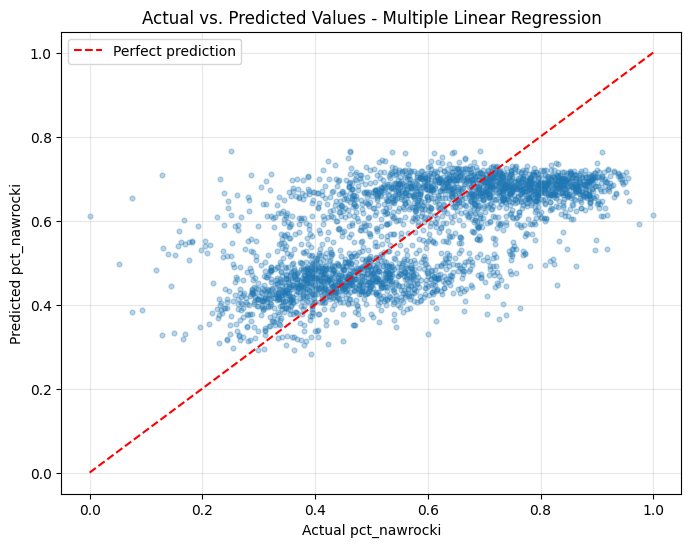

In [72]:
pred_plot_m = multiple_predictions.sample(min(3000, len(multiple_predictions)), random_state=RANDOM_STATE)

plt.figure(figsize=(8, 6))
plt.scatter(pred_plot_m["Actual"], pred_plot_m["Predicted"], alpha=0.3, s=12)
plt.plot([0, 1], [0, 1], linestyle="--", color="red", label="Perfect prediction")
plt.xlabel("Actual pct_nawrocki")
plt.ylabel("Predicted pct_nawrocki")
plt.title("Actual vs. Predicted Values - Multiple Linear Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [73]:
mae_multiple = mean_absolute_error(y_test_m, y_pred_multiple)
mse_multiple = mean_squared_error(y_test_m, y_pred_multiple)
rmse_multiple = np.sqrt(mse_multiple)
r_squared_multiple = r2_score(y_test_m, y_pred_multiple)
mape_multiple = calculate_mape(y_test_m, y_pred_multiple)

multiple_metrics = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "MAPE (%)", "R-squared"],
    "Value": [mae_multiple, mse_multiple, rmse_multiple, mape_multiple, r_squared_multiple]
})
display(multiple_metrics)

# Comparison with the simple model
comparison = pd.DataFrame({
    "Simple model": simple_metrics["Value"].values,
    "Multiple model": multiple_metrics["Value"].values
}, index=simple_metrics["Metric"])
display(comparison)

,Metric,Value
0,MAE,0.107425
1,MSE,0.017961
2,RMSE,0.134019
3,MAPE (%),22.523241
4,R-squared,0.431993


,Simple model,Multiple model
Metric,,
MAE,0.128095,0.107425
MSE,0.024950,0.017961
RMSE,0.157957,0.134019
MAPE (%),27.361370,22.523241
R-squared,0.210959,0.431993


In [74]:
new_stations_multiple = pd.DataFrame({
    "eligible_voters_k": [0.5, 2.0],
    "turnout": [0.70, 0.80],
    "share_certificate": [0.02, 0.05],
    "is_rural": [1, 0],
})
new_stations_multiple["predicted_pct_nawrocki"] = multiple_model.predict(new_stations_multiple[multiple_predictors])
display(new_stations_multiple)

,eligible_voters_k,turnout,share_certificate,is_rural,predicted_pct_nawrocki
0,0.5,0.7,0.02,1,0.669512
1,2.0,0.8,0.05,0,0.359754


# BINARY LOGIC REGRESSION

In [75]:
logistic_predictors = ["eligible_voters_k", "turnout", "share_certificate", "share_postal",
                       "share_proxy", "pct_invalid_votes", "is_rural"]

logistic_data = df_reg[logistic_predictors + ["winner"]].copy()

for column in logistic_predictors:
    logistic_data[column] = pd.to_numeric(logistic_data[column], errors="coerce")

logistic_data = logistic_data.dropna()
logistic_data["winner"] = logistic_data["winner"].astype(int)   # already coded 1 = Nawrocki, 0 = Trzaskowski

print("Dataset shape:", logistic_data.shape)
print("\nTarget variable distribution:")
print(logistic_data["winner"].value_counts())
display(logistic_data.head())

Dataset shape: (32038, 8)

Target variable distribution:
winner
1    19614
0    12424
Name: count, dtype: int64


,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural,winner
0,1.678,0.707390,0.016849,0.000000,0.000842,0.007582,0,0
1,1.269,0.717888,0.021954,0.000788,0.002195,0.008782,0,0
2,1.358,0.733432,0.019076,0.000736,0.002008,0.003012,0,0
3,1.354,0.726736,0.010163,0.000000,0.001016,0.009146,0,0
4,1.195,0.716318,0.016355,0.000000,0.001168,0.007009,0,0


In [76]:
print("Summary statistics for predictor variables")
display(logistic_data[logistic_predictors].describe())

print("Target variable proportions")
target_summary = pd.DataFrame({
    "Count": logistic_data["winner"].value_counts().sort_index(),
    "Percentage (%)": logistic_data["winner"].value_counts(normalize=True).sort_index().mul(100)
})
target_summary.index = ["Trzaskowski (0)", "Nawrocki (1)"]
display(target_summary)

Summary statistics for predictor variables


,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural
count,32038.000000,32038.000000,32038.000000,32038.000000,32038.000000,32038.000000,32038.000000
mean,0.915415,0.691558,0.020826,0.000292,0.001800,0.009472,0.541544
std,0.587057,0.093270,0.022761,0.000697,0.002551,0.008078,0.498279
min,0.006000,0.366667,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.426250,0.640155,0.008028,0.000000,0.000000,0.005305,0.000000
50%,0.828500,0.697212,0.015504,0.000000,0.000765,0.008363,1.000000
75%,1.318000,0.751488,0.025236,0.000000,0.002809,0.011749,1.000000
max,4.662000,0.899000,0.144928,0.003716,0.012478,0.059334,1.000000


Target variable proportions


,Count,Percentage (%)
Trzaskowski (0),12424,38.77895
Nawrocki (1),19614,61.22105


In [77]:
X = logistic_data[logistic_predictors]
y = logistic_data["winner"]

X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

print("Training observations:", len(X_train_l))
print("Testing observations:", len(X_test_l))
print("\nTraining target proportions:")
print(y_train_l.value_counts(normalize=True))
print("\nTesting target proportions:")
print(y_test_l.value_counts(normalize=True))

Training observations: 25630
Testing observations: 6408

Training target proportions:
winner
1    0.612212
0    0.387788
Name: proportion, dtype: float64

Testing target proportions:
winner
1    0.612203
0    0.387797
Name: proportion, dtype: float64


In [78]:
logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("logit", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))
])
logistic_model.fit(X_train_l, y_train_l)

# Predict probabilities
# Column 0 = probability of class 0 (Trzaskowski), column 1 = probability of class 1 (Nawrocki)
y_prob = logistic_model.predict_proba(X_test_l)[:, 1]

# Predict classes using the default threshold of 0.50
classification_threshold = 0.50
y_pred_l = (y_prob >= classification_threshold).astype(int)

print("Logistic regression model fitted successfully.")
print(f"Classification threshold = {classification_threshold}")

Logistic regression model fitted successfully.
Classification threshold = 0.5


In [79]:
logit_step = logistic_model.named_steps["logit"]
logistic_intercept = logit_step.intercept_[0]
logistic_coefficients = logit_step.coef_[0]

logistic_coefficients_table = pd.DataFrame({
    "Variable": logistic_predictors,
    "Coefficient": logistic_coefficients,
    "Odds_Ratio": np.exp(logistic_coefficients)
}).sort_values("Coefficient", key=abs, ascending=False)
display(logistic_coefficients_table)

print(f"Intercept = {logistic_intercept:.6f}")
print("\nLogistic regression equation (log-odds scale, predictors standardized: z = (x - mean) / std):")
equation = f"logit(p) = {logistic_intercept:.6f}"
for variable, coefficient in zip(logistic_predictors, logit_step.coef_[0]):
    equation += f" {'+' if coefficient >= 0 else '-'} {abs(coefficient):.6f} × z({variable})"
print(equation)
print("\np = P(winner = 1) = P(Nawrocki wins) = 1 / (1 + exp(-logit(p)))")
print("Odds ratio > 1: higher value of the variable increases the chance that Nawrocki wins; < 1: decreases it.")

,Variable,Coefficient,Odds_Ratio
6,is_rural,0.895211,2.447853
0,eligible_voters_k,-0.542634,0.581216
2,share_certificate,-0.400629,0.669898
1,turnout,-0.370702,0.690250
4,share_proxy,0.163389,1.177495
5,pct_invalid_votes,-0.158433,0.853480
3,share_postal,-0.100465,0.904417


Intercept = 0.655633

Logistic regression equation (log-odds scale, predictors standardized: z = (x - mean) / std):
logit(p) = 0.655633 - 0.542634 × z(eligible_voters_k) - 0.370702 × z(turnout) - 0.400629 × z(share_certificate) - 0.100465 × z(share_postal) + 0.163389 × z(share_proxy) - 0.158433 × z(pct_invalid_votes) + 0.895211 × z(is_rural)

p = P(winner = 1) = P(Nawrocki wins) = 1 / (1 + exp(-logit(p)))
Odds ratio > 1: higher value of the variable increases the chance that Nawrocki wins; < 1: decreases it.


In [80]:
logistic_predictions = X_test_l.copy()
logistic_predictions["Actual_Winner"] = y_test_l.values
logistic_predictions["Predicted_Probability_Nawrocki"] = y_prob
logistic_predictions["Predicted_Winner"] = y_pred_l
logistic_predictions["Predicted_Label"] = logistic_predictions["Predicted_Winner"].map({0: "Trzaskowski", 1: "Nawrocki"})

display(logistic_predictions.head(15))

,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural,Actual_Winner,Predicted_Probability_Nawrocki,Predicted_Winner,Predicted_Label
20354,0.420,0.716667,0.023256,0.000000,0.000000,0.000000,1,1,0.870892,1,Nawrocki
17850,1.453,0.727460,0.023652,0.000000,0.001892,0.005676,0,1,0.292835,0,Trzaskowski
20722,0.314,0.777070,0.000000,0.000000,0.000000,0.016393,1,1,0.864843,1,Nawrocki
16384,0.948,0.899000,0.137097,0.000000,0.000000,0.009217,0,0,0.035485,0,Trzaskowski
28304,0.927,0.717368,0.016541,0.000000,0.001504,0.013534,1,1,0.800141,1,Nawrocki
7909,0.199,0.758794,0.006623,0.000000,0.000000,0.000000,1,1,0.903780,1,Nawrocki
23354,1.218,0.647783,0.007605,0.000000,0.000000,0.007605,0,1,0.444948,0,Trzaskowski
26440,2.058,0.796404,0.016473,0.002430,0.004271,0.005495,0,0,0.144010,0,Trzaskowski
14977,0.212,0.778302,0.006061,0.000000,0.006061,0.000000,1,1,0.927398,1,Nawrocki
19805,0.690,0.617391,0.028169,0.000000,0.007042,0.021127,1,0,0.881116,1,Nawrocki


In [81]:
accuracy = accuracy_score(y_test_l, y_pred_l)
precision = precision_score(y_test_l, y_pred_l, zero_division=0)
recall = recall_score(y_test_l, y_pred_l, zero_division=0)
f1 = f1_score(y_test_l, y_pred_l, zero_division=0)
auc = roc_auc_score(y_test_l, y_prob)

classification_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Value": [accuracy, precision, recall, f1, auc]
})
display(classification_metrics)

,Metric,Value
0,Accuracy,0.775281
1,Precision,0.819727
2,Recall,0.811369
3,F1-score,0.815527
4,ROC-AUC,0.837394


Confusion matrix:
[[1785  700]
 [ 740 3183]]


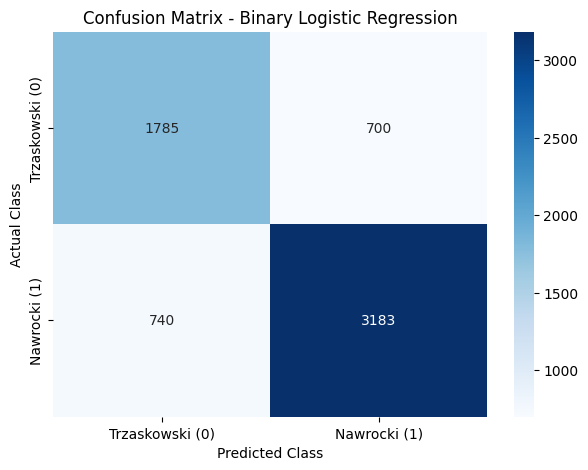

In [82]:
cm = confusion_matrix(y_test_l, y_pred_l, labels=[0, 1])
print("Confusion matrix:")
print(cm)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Trzaskowski (0)", "Nawrocki (1)"],
            yticklabels=["Trzaskowski (0)", "Nawrocki (1)"])
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - Binary Logistic Regression")
plt.show()

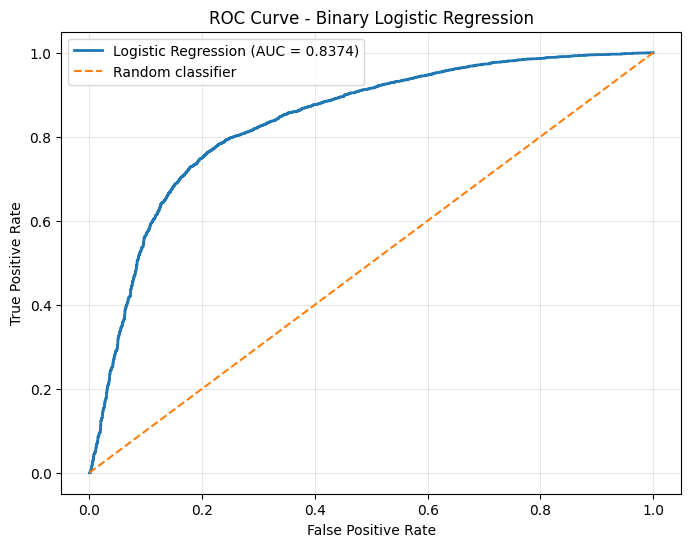

ROC-AUC = 0.8374


In [83]:
fpr, tpr, thresholds = roc_curve(y_test_l, y_prob)
roc_auc = roc_auc_score(y_test_l, y_prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2, label=f"Logistic Regression (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", linewidth=1.5, label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Binary Logistic Regression")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"ROC-AUC = {roc_auc:.4f}")

In [84]:

new_station = pd.DataFrame({
    "eligible_voters_k": [0.6],
    "turnout": [0.70],
    "share_certificate": [0.02],
    "share_postal": [0.0],
    "share_proxy": [0.002],
    "pct_invalid_votes": [0.01],
    "is_rural": [1],
})

probabilities = logistic_model.predict_proba(new_station[logistic_predictors])[0]
prob_trzaskowski, prob_nawrocki = probabilities[0], probabilities[1]
prediction = "Nawrocki" if logistic_model.predict(new_station[logistic_predictors])[0] == 1 else "Trzaskowski"

print("=" * 50)
print("LOGISTIC REGRESSION PREDICTION")
print("=" * 50)
print("\nInput values:")
display(new_station)
print(f"\nProbability of Trzaskowski: {prob_trzaskowski:.4f} ({prob_trzaskowski * 100:.2f}%)")
print(f"Probability of Nawrocki:    {prob_nawrocki:.4f} ({prob_nawrocki * 100:.2f}%)")
print(f"\nPredicted winner in this polling station: {prediction}")

LOGISTIC REGRESSION PREDICTION

Input values:


,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural
0,0.6,0.7,0.02,0.0,0.002,0.01,1



Probability of Trzaskowski: 0.1421 (14.21%)
Probability of Nawrocki:    0.8579 (85.79%)

Predicted winner in this polling station: Nawrocki


# CLASSIFICATION WITH DECISION TREES

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, confusion_matrix, classification_report
)

RANDOM_STATE = 42
CLASS_NAMES = ["Trzaskowski", "Nawrocki"]   # order matches classes_ = [0, 1]

print("Libraries loaded.")

Libraries loaded.


In [86]:
df_tree = df.copy()
df_tree["eligible_voters_k"] = df_tree["eligible_voters"] / 1000
df_tree["is_rural"] = (df_tree["area_type"] == "wieś").astype(int)

numeric_features = ["eligible_voters_k", "turnout", "share_certificate", "share_postal",
                    "share_proxy", "pct_invalid_votes", "is_rural"]

# Features and labels
X_tree = df_tree[numeric_features + ["voivodeship"]]
Y_tree = df_tree["winner"].astype(int)

# Converting categorical data to numbers (one-hot encoding)
X_encoded = pd.get_dummies(X_tree, columns=["voivodeship"], dtype=int)

print("Feature matrix shape:", X_encoded.shape)
print("\nTarget distribution:")
print(Y_tree.value_counts(normalize=True).rename(index={0: "Trzaskowski (0)", 1: "Nawrocki (1)"}))
display(X_encoded.head())

Feature matrix shape: (32038, 24)

Target distribution:
winner
Nawrocki (1)       0.612211
Trzaskowski (0)    0.387789
Name: proportion, dtype: float64


,eligible_voters_k,turnout,share_certificate,share_postal,share_proxy,pct_invalid_votes,is_rural,voivodeship_abroad/ship,voivodeship_dolnośląskie,voivodeship_kujawsko-pomorskie,...,voivodeship_opolskie,voivodeship_podkarpackie,voivodeship_podlaskie,voivodeship_pomorskie,voivodeship_warmińsko-mazurskie,voivodeship_wielkopolskie,voivodeship_zachodniopomorskie,voivodeship_łódzkie,voivodeship_śląskie,voivodeship_świętokrzyskie
0,1.678,0.707390,0.016849,0.000000,0.000842,0.007582,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
1,1.269,0.717888,0.021954,0.000788,0.002195,0.008782,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,1.358,0.733432,0.019076,0.000736,0.002008,0.003012,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,1.354,0.726736,0.010163,0.000000,0.001016,0.009146,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
4,1.195,0.716318,0.016355,0.000000,0.001168,0.007009,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0


In [87]:
x_train, x_test, y_train, y_test = train_test_split(
    X_encoded, Y_tree, test_size=0.3, random_state=RANDOM_STATE, stratify=Y_tree
)

print("Training observations:", len(x_train))
print("Testing observations: ", len(x_test))
print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(4))
print("\nTesting target proportions:")
print(y_test.value_counts(normalize=True).round(4))

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training observations: 22426
Testing observations:  9612

Training target proportions:
winner
1    0.6122
0    0.3878
Name: proportion, dtype: float64

Testing target proportions:
winner
1    0.6123
0    0.3877
Name: proportion, dtype: float64


In [88]:
classifier = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=None, min_samples_leaf=1)
classifier.fit(x_train, y_train)

y_pred_base = classifier.predict(x_test)

print(f"Accuracy on the training set: {classifier.score(x_train, y_train)*100:.2f}%")
print(f"Accuracy on the test set:     {accuracy_score(y_test, y_pred_base)*100:.2f}%")
print(f"\nTree depth: {classifier.get_depth()}, number of leaves: {classifier.get_n_leaves()}")

Accuracy on the training set: 100.00%
Accuracy on the test set:     78.69%

Tree depth: 36, number of leaves: 3058


In [89]:
depths = list(range(2, 21))
depth_results = []

for d in depths:
    clf = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(clf, x_train, y_train, cv=skf, scoring="accuracy")
    clf.fit(x_train, y_train)
    y_pred_d = clf.predict(x_test)
    depth_results.append({
        "max_depth": d,
        "Train accuracy": clf.score(x_train, y_train),
        "CV accuracy (mean)": cv_scores.mean(),
        "CV accuracy (std)": cv_scores.std(),
        "Test accuracy": accuracy_score(y_test, y_pred_d),
        "Test balanced accuracy": balanced_accuracy_score(y_test, y_pred_d),
        "Test F1": f1_score(y_test, y_pred_d),
        "Leaves": clf.get_n_leaves()
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df.round(4))

best_depth = int(depth_df.loc[depth_df["CV accuracy (mean)"].idxmax(), "max_depth"])
print(f"\nBest max_depth (highest CV accuracy): {best_depth}")

,max_depth,Train accuracy,CV accuracy (mean),CV accuracy (std),Test accuracy,Test balanced accuracy,Test F1,Leaves
0,2,0.7659,0.7672,0.0032,0.7639,0.7756,0.7897,4
1,3,0.7886,0.7852,0.0033,0.7825,0.7872,0.8117,8
2,4,0.8033,0.8012,0.0026,0.7939,0.7953,0.8242,16
3,5,0.8166,0.8123,0.0016,0.8064,0.8044,0.8372,32
4,6,0.8262,0.8201,0.0020,0.8113,0.8005,0.8463,60
5,7,0.8379,0.8249,0.0032,0.8186,0.8082,0.8522,103
6,8,0.8504,0.8323,0.0037,0.8253,0.8151,0.8578,169
7,9,0.8610,0.8334,0.0021,0.8273,0.8152,0.8604,268
8,10,0.8698,0.8293,0.0025,0.8259,0.8135,0.8594,399
9,11,0.8792,0.8280,0.0037,0.8248,0.8111,0.8591,553



Best max_depth (highest CV accuracy): 9


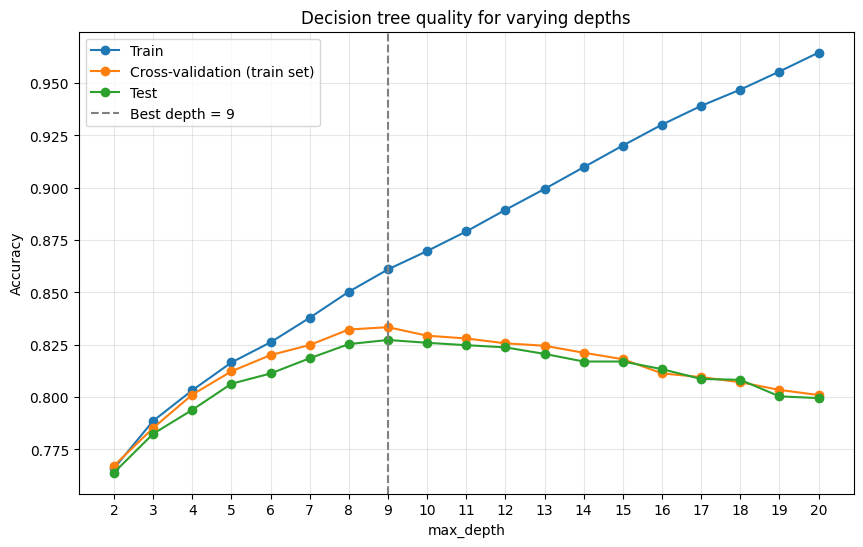

In [90]:
plt.figure(figsize=(10, 6))
plt.plot(depth_df["max_depth"], depth_df["Train accuracy"], marker="o", label="Train")
plt.plot(depth_df["max_depth"], depth_df["CV accuracy (mean)"], marker="o", label="Cross-validation (train set)")
plt.plot(depth_df["max_depth"], depth_df["Test accuracy"], marker="o", label="Test")
plt.axvline(best_depth, color="grey", linestyle="--", label=f"Best depth = {best_depth}")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Decision tree quality for varying depths")
plt.xticks(depths)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [91]:
leaf_values = [1, 2, 5, 10, 20, 50, 100, 200, 300, 500, 1000]
leaf_results = []

for m in leaf_values:
    clf = DecisionTreeClassifier(min_samples_leaf=m, random_state=RANDOM_STATE)
    cv_scores = cross_val_score(clf, x_train, y_train, cv=skf, scoring="accuracy")
    clf.fit(x_train, y_train)
    y_pred_m = clf.predict(x_test)
    leaf_results.append({
        "min_samples_leaf": m,
        "Train accuracy": clf.score(x_train, y_train),
        "CV accuracy (mean)": cv_scores.mean(),
        "CV accuracy (std)": cv_scores.std(),
        "Test accuracy": accuracy_score(y_test, y_pred_m),
        "Test balanced accuracy": balanced_accuracy_score(y_test, y_pred_m),
        "Test F1": f1_score(y_test, y_pred_m),
        "Depth": clf.get_depth(),
        "Leaves": clf.get_n_leaves()
    })

leaf_df = pd.DataFrame(leaf_results)
display(leaf_df.round(4))

best_leaf = int(leaf_df.loc[leaf_df["CV accuracy (mean)"].idxmax(), "min_samples_leaf"])
print(f"\nBest min_samples_leaf (highest CV accuracy): {best_leaf}")

,min_samples_leaf,Train accuracy,CV accuracy (mean),CV accuracy (std),Test accuracy,Test balanced accuracy,Test F1,Depth,Leaves
0,1,1.0000,0.7897,0.0089,0.7869,0.7739,0.8271,36,3058
1,2,0.9629,0.7846,0.0060,0.7815,0.7747,0.8186,35,2636
2,5,0.9163,0.8029,0.0050,0.7985,0.7871,0.8358,30,1622
3,10,0.8864,0.8170,0.0033,0.8125,0.8000,0.8483,28,1011
4,20,0.8670,0.8241,0.0018,0.8212,0.8071,0.8562,23,601
5,50,0.8500,0.8305,0.0031,0.8254,0.8124,0.8593,21,272
6,100,0.8388,0.8289,0.0017,0.8216,0.8047,0.8579,20,150
7,200,0.8294,0.8232,0.0037,0.8194,0.8002,0.8572,19,75
8,300,0.8171,0.7830,0.0031,0.8112,0.8044,0.8440,17,56
9,500,0.7812,0.7773,0.0024,0.7726,0.7588,0.8154,11,35



Best min_samples_leaf (highest CV accuracy): 50


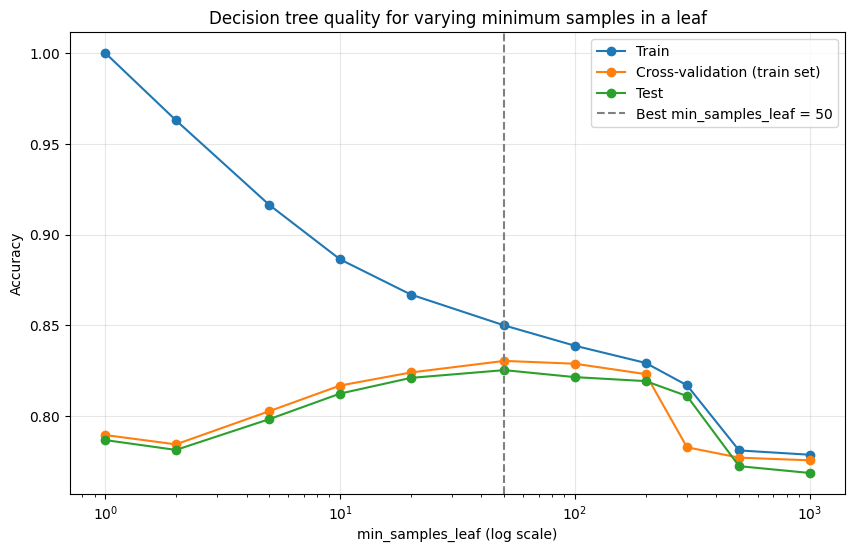

In [92]:
plt.figure(figsize=(10, 6))
plt.plot(leaf_df["min_samples_leaf"], leaf_df["Train accuracy"], marker="o", label="Train")
plt.plot(leaf_df["min_samples_leaf"], leaf_df["CV accuracy (mean)"], marker="o", label="Cross-validation (train set)")
plt.plot(leaf_df["min_samples_leaf"], leaf_df["Test accuracy"], marker="o", label="Test")
plt.axvline(best_leaf, color="grey", linestyle="--", label=f"Best min_samples_leaf = {best_leaf}")
plt.xscale("log")
plt.xlabel("min_samples_leaf (log scale)")
plt.ylabel("Accuracy")
plt.title("Decision tree quality for varying minimum samples in a leaf")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [93]:
candidates = {
    f"max_depth={best_depth}": dict(max_depth=best_depth),
    f"min_samples_leaf={best_leaf}": dict(min_samples_leaf=best_leaf),
    f"max_depth={best_depth} + min_samples_leaf={best_leaf}": dict(max_depth=best_depth, min_samples_leaf=best_leaf),
}

cand_rows = []
for name, params in candidates.items():
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, **params)
    cv = cross_val_score(clf, x_train, y_train, cv=skf, scoring="accuracy")
    cand_rows.append({"Variant": name, "CV accuracy (mean)": cv.mean(), "CV accuracy (std)": cv.std()})

cand_df = pd.DataFrame(cand_rows)
display(cand_df.round(4))

best_variant = cand_df.loc[cand_df["CV accuracy (mean)"].idxmax(), "Variant"]
print("Selected variant:", best_variant)

final_tree = DecisionTreeClassifier(random_state=RANDOM_STATE, **candidates[best_variant])
final_tree.fit(x_train, y_train)

,Variant,CV accuracy (mean),CV accuracy (std)
0,max_depth=9,0.8334,0.0021
1,min_samples_leaf=50,0.8305,0.0031
2,max_depth=9 + min_samples_leaf=50,0.8321,0.0031


Selected variant: max_depth=9


DecisionTreeClassifier(max_depth=9, random_state=42)

In [94]:
y_pred_tree = final_tree.predict(x_test)
y_prob_tree = final_tree.predict_proba(x_test)[:, 1]

tree_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Value": [
        accuracy_score(y_test, y_pred_tree),
        balanced_accuracy_score(y_test, y_pred_tree),
        precision_score(y_test, y_pred_tree),
        recall_score(y_test, y_pred_tree),
        f1_score(y_test, y_pred_tree),
        roc_auc_score(y_test, y_prob_tree),
    ]
})
display(tree_metrics.round(4))

print("Classification report:")
print(classification_report(y_test, y_pred_tree, target_names=CLASS_NAMES))

print("Model characteristics:")
print(f"  Parameters:       max_depth={final_tree.max_depth}, min_samples_leaf={final_tree.min_samples_leaf}")
print(f"  Tree depth:       {final_tree.get_depth()}")
print(f"  Number of leaves: {final_tree.get_n_leaves()}")
print(f"  Number of nodes:  {final_tree.tree_.node_count}")
print(f"  Train accuracy:   {final_tree.score(x_train, y_train):.4f}")
print(f"  Test accuracy:    {final_tree.score(x_test, y_test):.4f}")

,Metric,Value
0,Accuracy,0.8273
1,Balanced accuracy,0.8152
2,Precision,0.8519
3,Recall,0.8690
4,F1-score,0.8604
5,ROC-AUC,0.8782


Classification report:
              precision    recall  f1-score   support

 Trzaskowski       0.79      0.76      0.77      3727
    Nawrocki       0.85      0.87      0.86      5885

    accuracy                           0.83      9612
   macro avg       0.82      0.82      0.82      9612
weighted avg       0.83      0.83      0.83      9612

Model characteristics:
  Parameters:       max_depth=9, min_samples_leaf=1
  Tree depth:       9
  Number of leaves: 268
  Number of nodes:  535
  Train accuracy:   0.8610
  Test accuracy:    0.8273


In [95]:
importances = pd.Series(final_tree.feature_importances_, index=x_train.columns).sort_values(ascending=False)
display(importances.head(10).round(4).to_frame("Importance"))

,Importance
is_rural,0.5011
turnout,0.1558
eligible_voters_k,0.0709
voivodeship_podkarpackie,0.0408
voivodeship_lubelskie,0.0402
share_certificate,0.0389
voivodeship_mazowieckie,0.0304
voivodeship_małopolskie,0.0266
voivodeship_podlaskie,0.0201
voivodeship_świętokrzyskie,0.0136


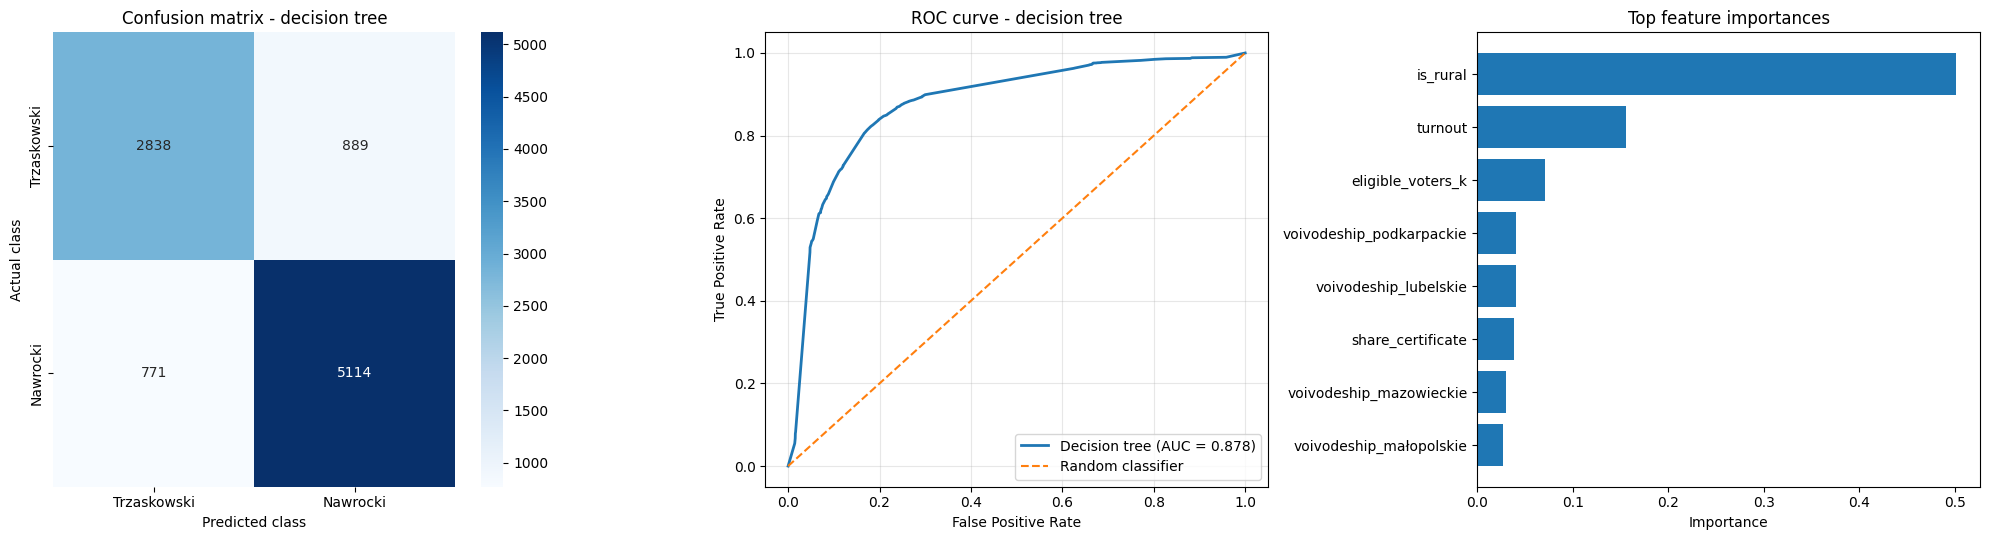

In [96]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# Confusion matrix
cm_tree = confusion_matrix(y_test, y_pred_tree, labels=[0, 1])
sns.heatmap(cm_tree, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
axes[0].set_xlabel("Predicted class")
axes[0].set_ylabel("Actual class")
axes[0].set_title("Confusion matrix - decision tree")

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob_tree)
axes[1].plot(fpr, tpr, linewidth=2, label=f"Decision tree (AUC = {roc_auc_score(y_test, y_prob_tree):.3f})")
axes[1].plot([0, 1], [0, 1], "--", label="Random classifier")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC curve - decision tree")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Feature importances
top = importances.head(8)[::-1]
axes[2].barh(top.index, top.values)
axes[2].set_xlabel("Importance")
axes[2].set_title("Top feature importances")

plt.tight_layout()
plt.show()

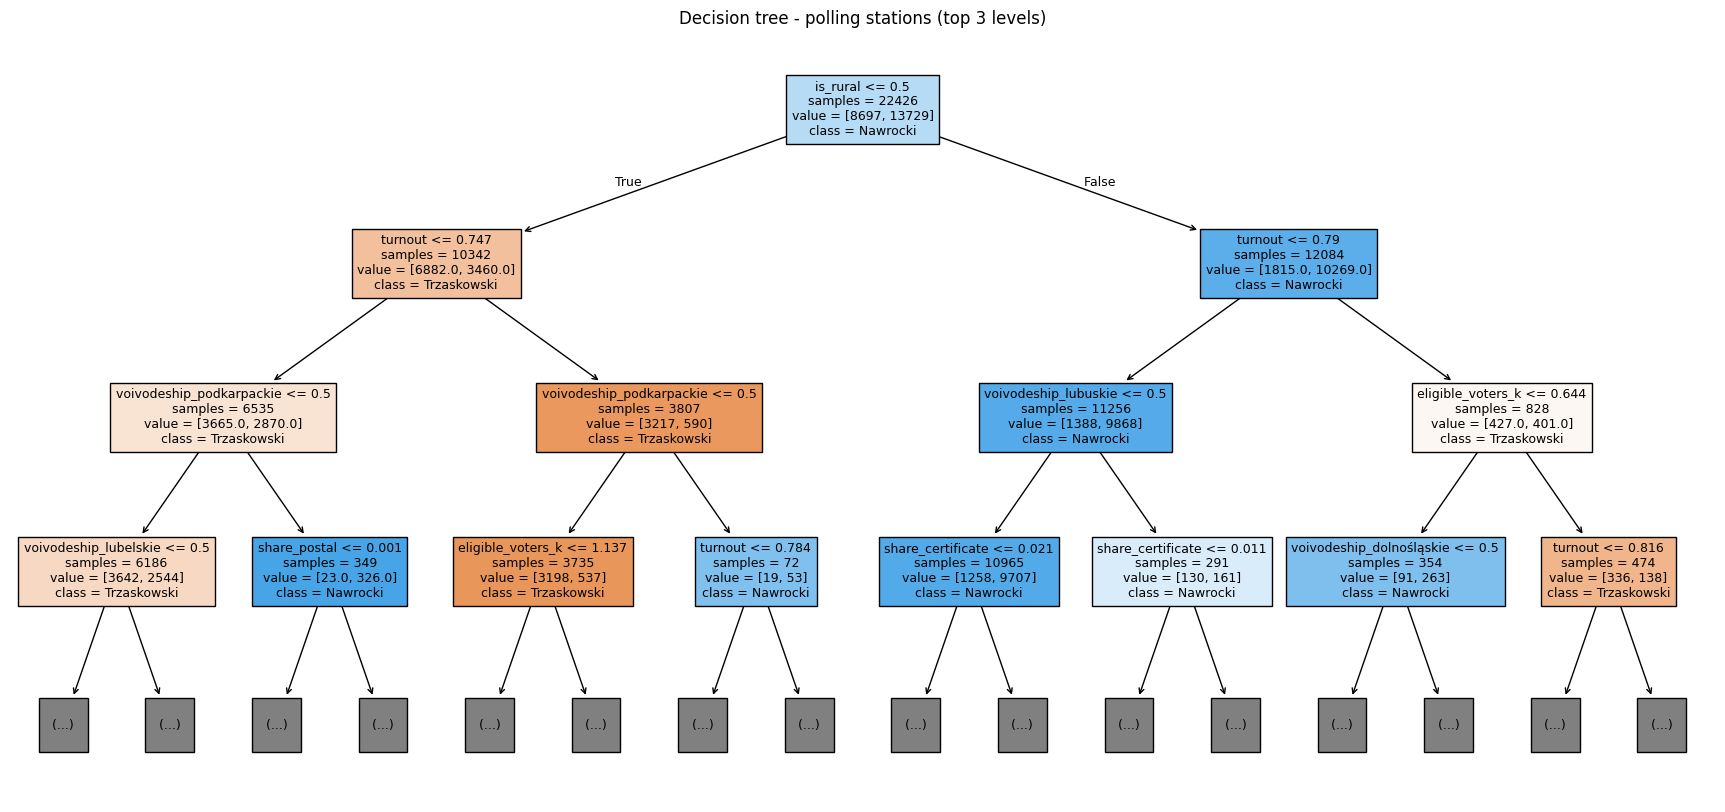

In [97]:
# Decision tree visualization (only the top levels are drawn so that the plot stays readable)
plt.figure(figsize=(22, 10))
plot_tree(final_tree, max_depth=3, filled=True, feature_names=list(x_train.columns),
          class_names=CLASS_NAMES, fontsize=9, proportion=False, impurity=False)
plt.title("Decision tree - polling stations (top 3 levels)")
plt.savefig("decision_tree.png", dpi=200, bbox_inches="tight")   # Save to PNG file
plt.show()

In [98]:
# Text form of the rules of a small, readable tree (depth 3)
small_tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE).fit(x_train, y_train)
print(export_text(small_tree, feature_names=list(x_train.columns)))

|--- is_rural <= 0.50
|   |--- turnout <= 0.75
|   |   |--- voivodeship_podkarpackie <= 0.50
|   |   |   |--- class: 0
|   |   |--- voivodeship_podkarpackie >  0.50
|   |   |   |--- class: 1
|   |--- turnout >  0.75
|   |   |--- voivodeship_podkarpackie <= 0.50
|   |   |   |--- class: 0
|   |   |--- voivodeship_podkarpackie >  0.50
|   |   |   |--- class: 1
|--- is_rural >  0.50
|   |--- turnout <= 0.79
|   |   |--- voivodeship_lubuskie <= 0.50
|   |   |   |--- class: 1
|   |   |--- voivodeship_lubuskie >  0.50
|   |   |   |--- class: 1
|   |--- turnout >  0.79
|   |   |--- eligible_voters_k <= 0.64
|   |   |   |--- class: 1
|   |   |--- eligible_voters_k >  0.64
|   |   |   |--- class: 0



In [99]:
def simplify(conditions):
    """Keep only the tightest bounds for every feature (e.g. turnout <= 0.79 AND turnout <= 0.75 -> turnout <= 0.75)."""
    upper, lower = {}, {}
    for feat, op, thr in conditions:
        if op == "<=":
            upper[feat] = min(thr, upper.get(feat, np.inf))
        else:
            lower[feat] = max(thr, lower.get(feat, -np.inf))
    out = []
    for feat in dict.fromkeys(f for f, _, _ in conditions):
        if feat in lower: out.append((feat, ">", lower[feat]))
        if feat in upper: out.append((feat, "<=", upper[feat]))
    return out


def extract_rules(fitted_tree, feature_names):
    """Convert every leaf of a fitted sklearn tree into a rule (list of conditions + class + support + confidence)."""
    t = fitted_tree.tree_
    rules = []

    def recurse(node, conditions):
        if t.children_left[node] == t.children_right[node]:      # leaf
            n = int(t.n_node_samples[node])
            cls = int(fitted_tree.classes_[np.argmax(t.value[node][0])])
            conf = float(np.max(t.value[node][0]) / t.value[node][0].sum())
            rules.append({"conditions": simplify(conditions), "class": cls, "support": n, "confidence": conf})
            return
        feat = feature_names[t.feature[node]]
        thr = t.threshold[node]
        recurse(t.children_left[node], conditions + [(feat, "<=", thr)])
        recurse(t.children_right[node], conditions + [(feat, ">", thr)])

    recurse(0, [])
    return rules


class RuleBasedClassifier:
    """Rule-based classifier: rules are checked in order of decreasing support; the first matching rule decides.
    If no rule matches, the default (majority) class is returned."""

    def __init__(self, rules, default_class):
        self.rules = sorted(rules, key=lambda r: (-r["support"], -r["confidence"]))
        self.default_class = default_class

    def _match(self, X, rule):
        mask = np.ones(len(X), dtype=bool)
        for feat, op, thr in rule["conditions"]:
            values = X[feat].values.astype(np.float32)      # sklearn trees compare in float32
            mask &= (values <= np.float32(thr)) if op == "<=" else (values > np.float32(thr))
        return mask

    def predict(self, X):
        pred = np.full(len(X), self.default_class)
        assigned = np.zeros(len(X), dtype=bool)
        for rule in self.rules:
            m = self._match(X, rule) & ~assigned
            pred[m] = rule["class"]
            assigned |= m
        return pred

    def predict_proba_yes(self, X):
        prob = np.full(len(X), 0.5)
        assigned = np.zeros(len(X), dtype=bool)
        for rule in self.rules:
            m = self._match(X, rule) & ~assigned
            prob[m] = rule["confidence"] if rule["class"] == 1 else 1 - rule["confidence"]
            assigned |= m
        return prob


def rule_to_text(rule):
    cond = " AND ".join(f"{f} {op} {thr:.3f}" for f, op, thr in rule["conditions"])
    return f"IF {cond} THEN winner = {CLASS_NAMES[rule['class']]}  (support={rule['support']}, confidence={rule['confidence']:.2f})"


all_rules = extract_rules(final_tree, list(x_train.columns))
default_class = int(y_train.mode()[0])
print("Number of rules extracted from the final tree:", len(all_rules))

print("\nThe 5 rules with the largest support:")
for r in sorted(all_rules, key=lambda r: -r["support"])[:5]:
    print(" -", rule_to_text(r))

Number of rules extracted from the final tree: 268

The 5 rules with the largest support:
 - IF is_rural > 0.500 AND turnout <= 0.790 AND voivodeship_lubuskie <= 0.500 AND share_certificate <= 0.021 AND voivodeship_opolskie <= 0.500 AND voivodeship_wielkopolskie <= 0.500 AND voivodeship_zachodniopomorskie <= 0.500 AND voivodeship_pomorskie <= 0.500 AND voivodeship_śląskie <= 0.500 THEN winner = Nawrocki  (support=6104, confidence=0.96)
 - IF is_rural <= 0.500 AND turnout <= 0.747 AND voivodeship_podkarpackie <= 0.500 AND voivodeship_lubelskie <= 0.500 AND voivodeship_mazowieckie <= 0.500 AND eligible_voters_k > 0.550 AND voivodeship_podlaskie <= 0.500 AND voivodeship_małopolskie <= 0.500 AND voivodeship_świętokrzyskie <= 0.500 THEN winner = Trzaskowski  (support=3840, confidence=0.77)
 - IF is_rural > 0.500 AND turnout <= 0.750 AND voivodeship_lubuskie <= 0.500 AND share_certificate > 0.021 AND voivodeship_lubelskie <= 0.500 AND voivodeship_mazowieckie <= 0.500 AND voivodeship_podkarpa

In [100]:
def evaluate(name, y_true, y_pred, y_prob, n_rules=None):
    return {
        "Classifier": name,
        "Rules": n_rules,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-score": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
    }

rows = [evaluate("Decision tree (final)", y_test, y_pred_tree, y_prob_tree, final_tree.get_n_leaves())]

rule_sets = {
    "Rules: all leaves": all_rules,
    "Rules: support >= 50, confidence >= 0.60": [r for r in all_rules if r["support"] >= 50 and r["confidence"] >= 0.60],
    "Rules: support >= 200, confidence >= 0.65": [r for r in all_rules if r["support"] >= 200 and r["confidence"] >= 0.65],
}

rule_classifiers = {}
for name, rs in rule_sets.items():
    rbc = RuleBasedClassifier(rs, default_class)
    rule_classifiers[name] = rbc
    rows.append(evaluate(name, y_test, rbc.predict(x_test), rbc.predict_proba_yes(x_test), len(rs)))

comparison_rules = pd.DataFrame(rows)
display(comparison_rules.round(4))

same = (rule_classifiers["Rules: all leaves"].predict(x_test) == y_pred_tree).mean()
print(f"\nAgreement between the tree and the rule set made of all leaves: {same*100:.2f}%")

,Classifier,Rules,Accuracy,Balanced accuracy,Precision,Recall,F1-score,ROC-AUC
0,Decision tree (final),268,0.8273,0.8152,0.8519,0.8690,0.8604,0.8782
1,Rules: all leaves,268,0.8273,0.8152,0.8519,0.8690,0.8604,0.8782
2,"Rules: support >= 50, confidence >= 0.60",44,0.8164,0.7915,0.8168,0.9025,0.8575,0.8875
3,"Rules: support >= 200, confidence >= 0.65",16,0.8029,0.7695,0.7928,0.9179,0.8508,0.8655



Agreement between the tree and the rule set made of all leaves: 100.00%


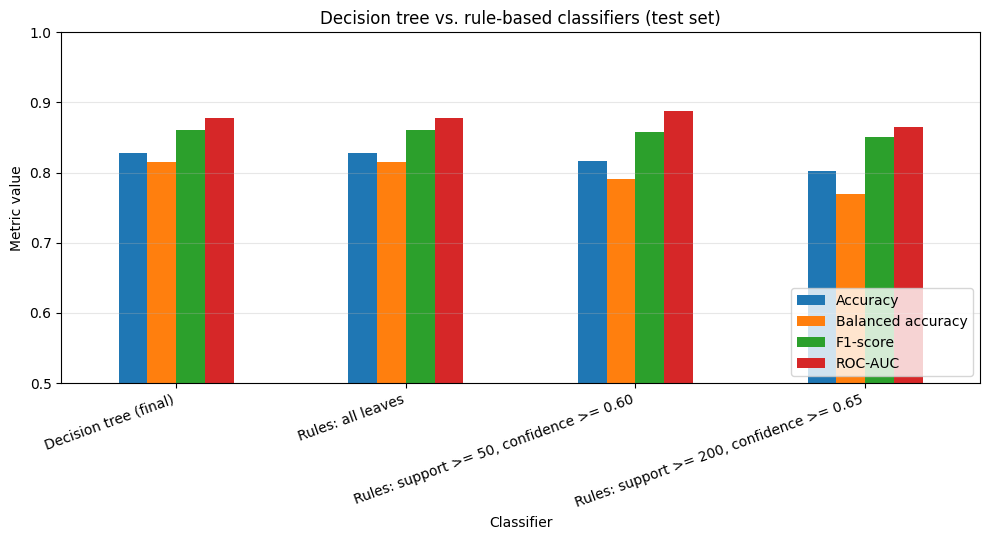

In [101]:
plt.figure(figsize=(10, 5.5))
metrics_to_plot = ["Accuracy", "Balanced accuracy", "F1-score", "ROC-AUC"]
comparison_rules.set_index("Classifier")[metrics_to_plot].plot(kind="bar", ax=plt.gca())
plt.ylim(0.5, 1.0)
plt.ylabel("Metric value")
plt.title("Decision tree vs. rule-based classifiers (test set)")
plt.xticks(rotation=20, ha="right")
plt.grid(True, axis="y", alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [102]:
chosen = rule_sets["Rules: support >= 200, confidence >= 0.65"]
print(f"Number of rules: {len(chosen)}\n")
for r in sorted(chosen, key=lambda r: -r["support"])[:10]:
    print(" -", rule_to_text(r))

Number of rules: 16

 - IF is_rural > 0.500 AND turnout <= 0.790 AND voivodeship_lubuskie <= 0.500 AND share_certificate <= 0.021 AND voivodeship_opolskie <= 0.500 AND voivodeship_wielkopolskie <= 0.500 AND voivodeship_zachodniopomorskie <= 0.500 AND voivodeship_pomorskie <= 0.500 AND voivodeship_śląskie <= 0.500 THEN winner = Nawrocki  (support=6104, confidence=0.96)
 - IF is_rural <= 0.500 AND turnout <= 0.747 AND voivodeship_podkarpackie <= 0.500 AND voivodeship_lubelskie <= 0.500 AND voivodeship_mazowieckie <= 0.500 AND eligible_voters_k > 0.550 AND voivodeship_podlaskie <= 0.500 AND voivodeship_małopolskie <= 0.500 AND voivodeship_świętokrzyskie <= 0.500 THEN winner = Trzaskowski  (support=3840, confidence=0.77)
 - IF is_rural > 0.500 AND turnout <= 0.750 AND voivodeship_lubuskie <= 0.500 AND share_certificate > 0.021 AND voivodeship_lubelskie <= 0.500 AND voivodeship_mazowieckie <= 0.500 AND voivodeship_podkarpackie <= 0.500 AND voivodeship_małopolskie <= 0.500 THEN winner = Nawr

# CLUSTERING ANALYSIS

Can polling stations be grouped into distinct profiles based on their size, turnout, and voting characteristics?

In [103]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

cluster_features = [
    "turnout",
    "eligible_voters",
    "pct_invalid_votes",
    "share_certificate",
    "share_proxy"
]

cluster_data = df[cluster_features].dropna().copy()

scaler_cluster = StandardScaler()
X_cluster = scaler_cluster.fit_transform(cluster_data)

print("Number of observations:", len(cluster_data))
print("Features used:")
print(cluster_features)

Number of observations: 32038
Features used:
['turnout', 'eligible_voters', 'pct_invalid_votes', 'share_certificate', 'share_proxy']


In [104]:
# Test different values of k
k_values = range(2, 8)

inertias = []
silhouette_scores = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    inertias.append(kmeans.inertia_)
    silhouette_scores.append(
        silhouette_score(
            X_cluster,
            labels,
            sample_size=min(5000, len(X_cluster)),
            random_state=42
        )
    )

results = pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette score": silhouette_scores
})

display(results)

,k,Inertia,Silhouette score
0,2,130966.262396,0.209019
1,3,110102.967784,0.239425
2,4,91879.548386,0.254377
3,5,74631.235445,0.272187
4,6,66946.701367,0.218995
5,7,61918.077141,0.192693



## Elbow method

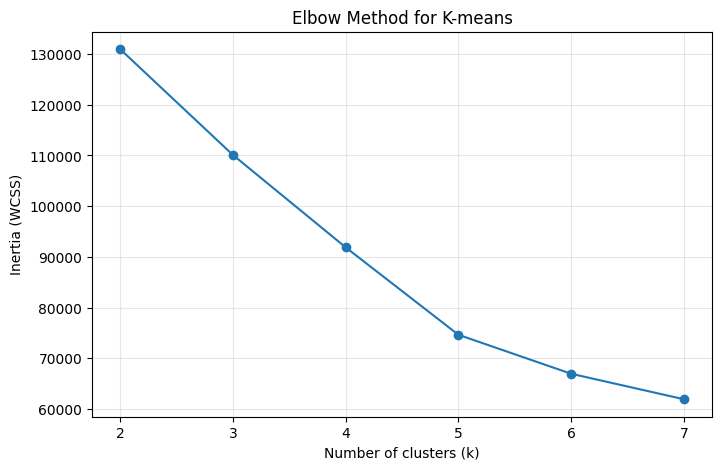

In [105]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, inertias, marker="o")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method for K-means")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

## Silhouette score

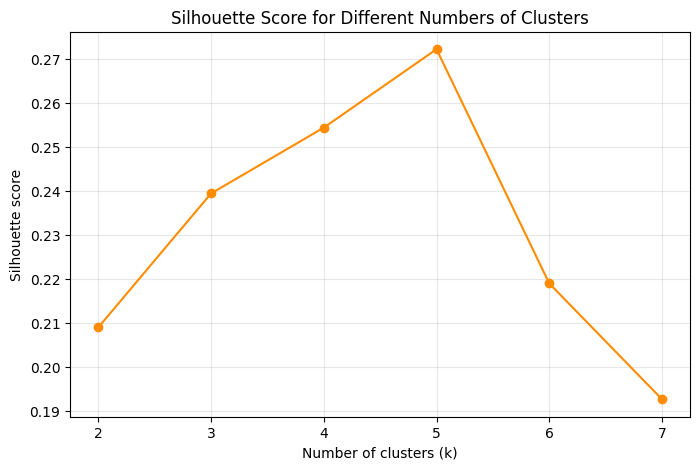

In [106]:
plt.figure(figsize=(8, 5))

plt.plot(k_values, silhouette_scores, marker="o", color="darkorange")

plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score for Different Numbers of Clusters")

plt.xticks(list(k_values))
plt.grid(alpha=0.3)

plt.show()

In [107]:
best_k = int(results.loc[
    results["Silhouette score"].idxmax(),
    "k"
])

print("Best number of clusters according to silhouette score:", best_k)

Best number of clusters according to silhouette score: 5


In [108]:
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_data["cluster"] = final_kmeans.fit_predict(X_cluster)

print(cluster_data["cluster"].value_counts().sort_index())

cluster
0    11325
1     4877
2    13807
3     1315
4      714
Name: count, dtype: int64


## Centroids

In [109]:
centroids_original = scaler_cluster.inverse_transform(
    final_kmeans.cluster_centers_
)

centroids_df = pd.DataFrame(
    centroids_original,
    columns=cluster_features
)

centroids_df.index = [
    f"Cluster {i}" for i in range(best_k)
]

display(centroids_df.round(3))


,turnout,eligible_voters,pct_invalid_votes,share_certificate,share_proxy
Cluster 0,0.751,1516.747,0.009,0.021,0.002
Cluster 1,0.674,741.197,0.008,0.018,0.007
Cluster 2,0.654,556.828,0.008,0.014,0.000
Cluster 3,0.706,579.085,0.009,0.105,0.001
Cluster 4,0.564,122.192,0.049,0.015,0.000


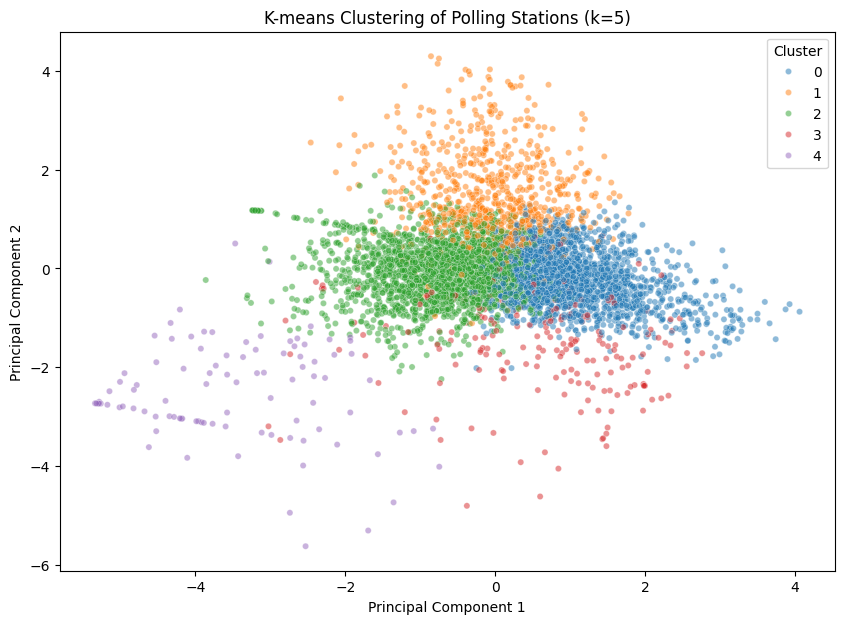

In [110]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "cluster": cluster_data["cluster"].values
})

sample_plot = plot_df.sample(
    min(5000, len(plot_df)),
    random_state=42
)

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=sample_plot,
    x="PC1",
    y="PC2",
    hue="cluster",
    palette="tab10",
    alpha=0.5,
    s=20
)

plt.title(f"K-means Clustering of Polling Stations (k={best_k})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")

plt.show()

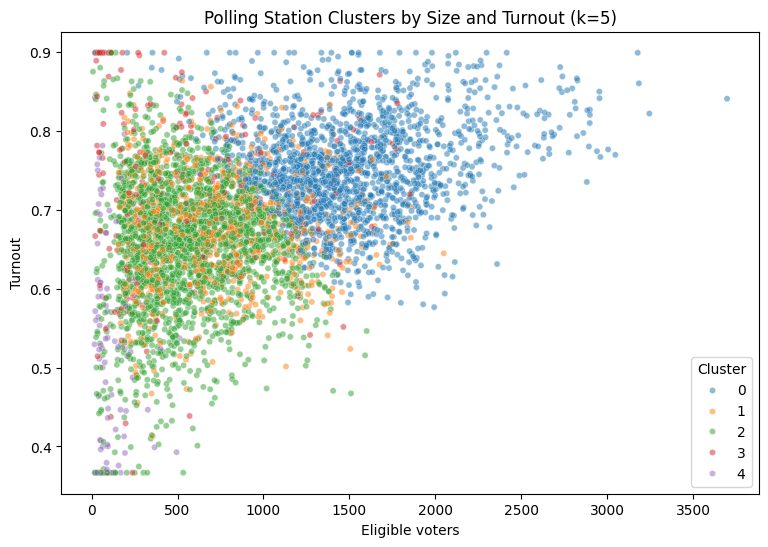

In [111]:
cluster_data["area_type"] = df.loc[cluster_data.index, "area_type"]
cluster_data["winner"] = df.loc[cluster_data.index, "winner"]

sample_plot = cluster_data.sample(
    min(5000, len(cluster_data)),
    random_state=42
)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=sample_plot,
    x="eligible_voters",
    y="turnout",
    hue="cluster",
    palette="tab10",
    alpha=0.5,
    s=20
)

plt.xlabel("Eligible voters")
plt.ylabel("Turnout")
plt.title(f"Polling Station Clusters by Size and Turnout (k={best_k})")
plt.legend(title="Cluster")

plt.show()

In [112]:
winner_by_cluster = pd.crosstab(
    cluster_data["cluster"],
    cluster_data["winner"],
    normalize="index"
) * 100

winner_by_cluster.columns = [
    "Trzaskowski",
    "Nawrocki"
]

display(winner_by_cluster.round(2))

,Trzaskowski,Nawrocki
cluster,,
0,65.78,34.22
1,25.45,74.55
2,19.71,80.29
3,59.85,40.15
4,31.51,68.49


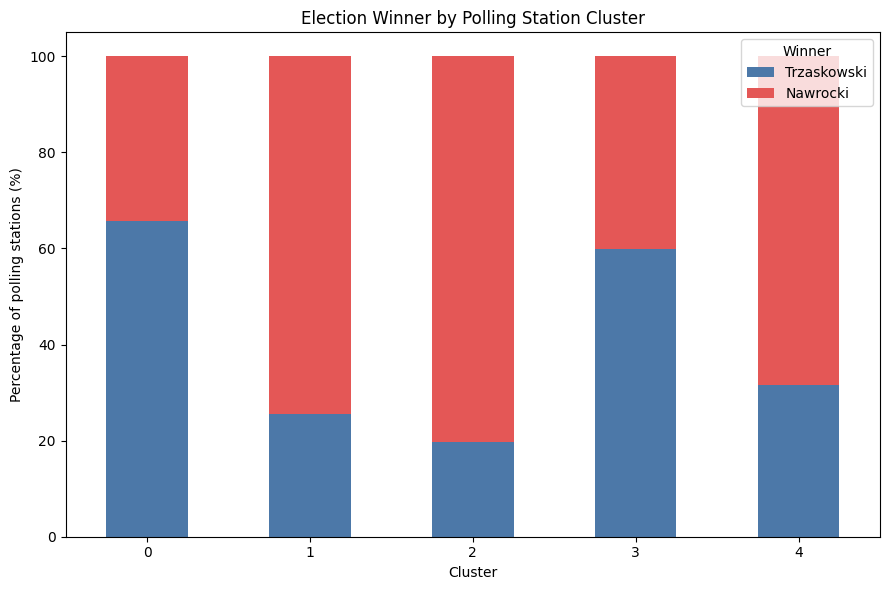

In [113]:
winner_by_cluster.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 6),
    color=["#4C78A8", "#E45756"]
)

plt.ylabel("Percentage of polling stations (%)")
plt.xlabel("Cluster")
plt.title("Election Winner by Polling Station Cluster")
plt.legend(title="Winner")
plt.xticks(rotation=0)
plt.tight_layout()

plt.show()


K-means (k = 5) grouped polling stations mainly by size and turnout. The silhouette score is low (0.27), so the clusters are descriptive profiles rather than clearly separated groups.

Large stations (cluster 0) have the highest turnout (75%) and are mostly won by Trzaskowski (66%).
Small and medium stations (clusters 1 and 2) are the most typical and are mostly won by Nawrocki (75-80%).
Clusters 3 and 4 are small, atypical groups (many voting certificates; very small stations with high invalid votes).

The winner was not used for clustering, yet it differs strongly between clusters. This confirms that larger, higher-turnout stations favour Trzaskowski and smaller ones favour Nawrocki.